# Loyalytics: Análisis exploratorio, imputación y modelado predictivo de Churn

**Modelos y Simulación de Sistemas II - Universidad de Antioquia**

Este proyecto desarrolla el ciclo completo de ciencia de datos para Loyalytics, cuyo objetivo es predecir el abandono de clientes (*Churn*) en una plataforma de comercio electrónico. Este notebook cubre el análisis exploratorio y la imputación; el modelado y la evaluación se desarrollan en `3_trainig.ipynb`, `4_evaluation.ipynb` y `5_pca_umap.ipynb`.

Se estudia la composición y calidad de los datos, la distribución de las variables, sus relaciones con la variable objetivo y los patrones presentes en los datos faltantes. Posteriormente, se comparan diferentes estrategias de imputación y técnicas de reducción de dimensionalidad para estructurar un flujo de procesamiento robusto. Finalmente, se entrenan y sintonizan diversos modelos clasificadores mediante validación cruzada y se realiza una evaluación final sobre el conjunto de prueba utilizando métricas orientadas al negocio.

Los análisis que orientan las decisiones del proyecto se realizan sobre el conjunto de entrenamiento, manteniendo el conjunto de prueba fuera de las decisiones de EDA e imputación para evitar la fuga de datos (*data leakage*).

### Estructura del proyecto

1. **Configuración y diccionario de variables.**
2. **Homologación de categorías, auditoría de duplicados y partición de los datos.**
3. **Diagnóstico de datos faltantes y análisis de sus patrones.**
4. **Análisis univariado según la naturaleza de las variables.**
5. **Análisis de asociaciones con Churn y relaciones entre características.**
6. **Visualización multivariada y comportamiento de perfiles con datos faltantes.**
7. **Comparación de estrategias de imputación mediante validación cruzada.**
8. **Resumen ejecutivo de hallazgos del EDA y decisiones de arquitectura.**
9. **Preprocesamiento y técnicas de reducción de dimensionalidad (PCA y UMAP).**
10. **Metodología y entrenamiento de modelos (Regresión Logística, KNN, Random Forest, SVM, MLP).**
11. **Modelo de referencia (HistGradientBoosting), sintonización fina y comparación de modelos (CV 5x5).**
12. **Evaluación final en el conjunto de prueba, análisis de negocio (curva de ganancia/lift) y conclusiones.**

## 0. Diccionario de variables

Fuente: *E-Commerce Customer Churn Analysis and Prediction Dataset* (Kaggle).

El conjunto de datos contiene características relacionadas con la permanencia, comportamiento de compra, preferencias y satisfacción de los clientes. Estas variables se clasifican según su naturaleza para aplicar los análisis estadísticos correspondientes.

| Variable | Significado | Naturaleza | Grupo de análisis | Valores / Codificación |
| :--- | :--- | :--- | :--- | :--- |
| `CustomerID` | Identificador del cliente. | Identificador | Excluida de los predictores | 50.001 a 55.630 |
| `Churn` | Indica si el cliente abandonó la plataforma. | Binaria | Variable objetivo | 0: Retenido, 1: Abandono |
| `Tenure` | Tiempo de permanencia del cliente. | Numérica | `cont_cols` | 0 a 61 |
| `WarehouseToHome` | Distancia entre el almacén y el hogar del cliente. | Numérica | `cont_cols` | 5 a 127 |
| `DaySinceLastOrder` | Tiempo transcurrido desde el último pedido. | Numérica | `cont_cols` | 0 a 46 |
| `CashbackAmount` | Cantidad recibida mediante cashback. | Numérica | `cont_cols` | 0 a 324,99 |
| `NumberOfAddress` | Número de direcciones registradas. | Discreta | `disc_cols` | 1 a 22 |
| `OrderAmountHikeFromlastYear` | Incremento del monto de los pedidos respecto al año anterior. | Discreta | `disc_cols` | 11 a 26 |
| `CouponUsed` | Número de cupones utilizados. | Discreta | `disc_cols` | 0 a 16 |
| `OrderCount` | Número de pedidos realizados. | Discreta | `disc_cols` | 1 a 16 |
| `CityTier` | Clasificación de la ciudad del cliente. | Ordinal | `ord_cols` | 1 a 3 |
| `SatisfactionScore` | Puntuación de satisfacción del cliente. | Ordinal | `ord_cols` | 1 a 5 |
| `HourSpendOnApp` | Tiempo dedicado a la aplicación. | Discreta (numérica) | `disc_cols` | 0 a 5 |
| `NumberOfDeviceRegistered` | Número de dispositivos registrados. | Discreta (numérica) | `disc_cols` | 1 a 6 |
| `PreferredLoginDevice` | Dispositivo preferido para iniciar sesión. | Nominal | `nom_cols` | Computer, Mobile Phone |
| `PreferredPaymentMode` | Método de pago preferido. | Nominal | `nom_cols` | Debit Card, Credit Card, E wallet, UPI, Cash on Delivery |
| `Gender` | Género registrado del cliente. | Nominal | `nom_cols` | Male, Female |
| `PreferedOrderCat` | Categoría de productos preferida. | Nominal | `nom_cols` | Laptop & Accessory, Mobile Phone, Fashion, Grocery, Others |
| `MaritalStatus` | Estado civil del cliente. | Nominal | `nom_cols` | Married, Single, Divorced |
| `Complain` | Indica si el cliente ha presentado una queja. | Binaria | `bin_cols` | 0, 1 |

## 1. Configuración, carga, verificación del diccionario y auditoría de duplicados

In [1]:
import os
from pathlib import Path

_CLAVES_RUTA = {
    "MPLCONFIGDIR", "NUMBA_CACHE_DIR", "KAGGLEHUB_CACHE", "KAGGLE_CONFIG_DIR",
    "JUPYTER_CONFIG_DIR", "JUPYTER_DATA_DIR", "IPYTHONDIR", "DIR_FIGS", "DIR_TABLAS",
}

def cargar_env(nombre=".env", max_niveles=4):
    """Lee 'CLAVE=valor' del .env local sin sobrescribir variables ya definidas."""
    p = Path.cwd().resolve()
    for _ in range(max_niveles):
        if (p / nombre).is_file():
            ruta = p / nombre
            break
        if p.parent == p:
            return None
        p = p.parent
    else:
        return None

    for linea in ruta.read_text(encoding="utf-8").splitlines():
        linea = linea.strip()
        if not linea or linea.startswith("#") or "=" not in linea:
            continue
        clave, valor = (parte.strip() for parte in linea.split("=", 1))
        valor = valor.strip('"').strip("'")
        if clave and clave not in os.environ:
            if clave in _CLAVES_RUTA and valor and not Path(valor).is_absolute():
                valor = str((ruta.parent / valor).resolve())
            os.environ[clave] = valor
    return ruta

_RUTA_ENV = cargar_env()
print(f"Configuración local: {_RUTA_ENV}" if _RUTA_ENV else "Configuración local: sin .env, valores por defecto")

try:
    import openpyxl
except ImportError as exc:
    raise ImportError(
        "Falta 'openpyxl', necesaria para leer el .xlsx. Instálala antes de ejecutar: "
        "pip install openpyxl"
    ) from exc

import os, sys, glob, warnings, random
raiz = Path.cwd().resolve()
candidatas_raiz = [raiz, *raiz.parents]

# En Colab el repositorio puede estar en /content/<nombre-repo>, no en el CWD.
for base in (Path("/content"), Path("/workspace"), Path("/mnt/data")):
    if base.is_dir():
        candidatas_raiz.extend(hijo for hijo in base.iterdir() if hijo.is_dir())

for candidato in candidatas_raiz:
    if (candidato / "src").is_dir() and (candidato / "notebooks").is_dir():
        sys.path.insert(0, str(candidato))
        break
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.svm import LinearSVC
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from src.comun import (SEED, BETA_UMBRAL, COSTO_FN, COSTO_FP,
    DIR_FIGS, DIR_TABLAS, RAIZ, DATASET_NOMBRE, guardar, exportar,
    guardar_estado, cargar_estado, GroupMedianImputer, construir_preprocesador,
    configurar_columnas)

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

EDA_SOBRE = "train"
ALPHA = 0.05
COLORES = {0: "#4c72b0", 1: "#dd8452"}

DIR_FIGS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)

print(f"Raiz del proyecto: {RAIZ}")
print(f"Figuras -> {DIR_FIGS}")
print(f"Tablas  -> {DIR_TABLAS}")

Configuración local: sin .env, valores por defecto


c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raiz del proyecto: C:\Users\ASUS\Desktop\V8-final
Figuras -> C:\Users\ASUS\Desktop\V8-final\reports\figures
Tablas  -> C:\Users\ASUS\Desktop\V8-final\reports


In [2]:
def cargar_dataset():
    candidatas = []
    for base in (RAIZ, Path.cwd()):
        candidatas += [base / DATASET_NOMBRE, base / "E Commerce Dataset.csv"]

    for ruta in candidatas:
        if ruta.exists():
            print(f"Dataset cargado desde: {ruta}")
            return pd.read_excel(ruta, sheet_name="E Comm") if ruta.suffix == ".xlsx" else pd.read_csv(ruta)

    try:
        import kagglehub
        destino = kagglehub.dataset_download("ankitverma2010/ecommerce-customer-churn-analysis-and-prediction")
        archivo = glob.glob(os.path.join(destino, "**", "*.xlsx"), recursive=True)[0]
        print(f"Dataset descargado en: {archivo}")
    except Exception as e:
        print("Descarga automática no disponible:", type(e).__name__, "-> sube el archivo manualmente")
        from google.colab import files  # solo disponible en Colab
        archivo = list(files.upload().keys())[0]

    return pd.read_excel(archivo, sheet_name="E Comm") if archivo.endswith(".xlsx") else pd.read_csv(archivo)

df_raw = cargar_dataset()
df_raw.columns = df_raw.columns.str.strip()

print(f"Dimensiones del dataset crudo: {df_raw.shape}")

df_raw.head()

Dataset descargado en: C:\Users\ASUS\.cache\kagglehub\datasets\ankitverma2010\ecommerce-customer-churn-analysis-and-prediction\versions\1\E Commerce Dataset.xlsx
Dimensiones del dataset crudo: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


Se establece el entorno técnico y se carga con éxito el dataset original, confirmando sus dimensiones crudas de 5,630 filas y 20 columnas.
Se instaura explícitamente la regla metodológica más crítica del proyecto: todo el análisis y las decisiones de preprocesamiento se ejecutarán estrictamente sobre el conjunto train para evitar la fuga de datos (data leakage).

In [4]:
TARGET, ID_COL = "Churn", "CustomerID"

nom_cols  = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender", "PreferedOrderCat", "MaritalStatus"]
ord_cols  = ["CityTier", "SatisfactionScore"]
bin_cols  = ["Complain"]
cont_cols = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount"]
disc_cols = ["NumberOfAddress", "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount", "HourSpendOnApp", "NumberOfDeviceRegistered"]

num_cols  = cont_cols + disc_cols
cat_vars  = nom_cols + ord_cols + bin_cols

todas_declaradas = nom_cols + ord_cols + bin_cols + cont_cols + disc_cols + [TARGET, ID_COL]
faltan = [c for c in todas_declaradas if c not in df_raw.columns]
assert not faltan, f"Columnas del diccionario que no están en los datos: {faltan}"
extra = [c for c in df_raw.columns if c not in todas_declaradas]
print("Columnas en los datos que no están en el diccionario:", extra or "ninguna")

DECLARADO = {
    "CustomerID": (50001, 55630, 0.0), "Tenure": (0, 61, 4.69), "CityTier": (1, 3, 0.0),
    "WarehouseToHome": (5, 127, 4.46), "HourSpendOnApp": (0, 5, 4.53), "NumberOfDeviceRegistered": (1, 6, 0.0),
    "SatisfactionScore": (1, 5, 0.0), "NumberOfAddress": (1, 22, 0.0), "Complain": (0, 1, 0.0),
    "OrderAmountHikeFromlastYear": (11, 26, 4.71), "CouponUsed": (0, 16, 4.55), "OrderCount": (1, 16, 4.58),
    "DaySinceLastOrder": (0, 46, 5.45), "CashbackAmount": (0, 324.99, 0.0), "Churn": (0, 1, 0.0)
}

filas = []

for c, (mn, mx, pna) in DECLARADO.items():
    obs = (df_raw[c].min(), df_raw[c].max(), round(100 * df_raw[c].isna().mean(), 2))
    ok = np.isclose(obs[0], mn) and np.isclose(obs[1], mx) and abs(obs[2] - pna) <= 0.05
    filas.append({
        "variable": c, "min_decl": mn, "min_obs": obs[0], "max_decl": mx, "max_obs": obs[1],
        "%NA_decl": pna, "%NA_obs": obs[2], "estado": "coincide" if ok else "REVISAR"
    })

verif = pd.DataFrame(filas).set_index("variable")
display(verif)
exportar(verif, "01_verificacion_diccionario")

Columnas en los datos que no están en el diccionario: ninguna


,min_decl,min_obs,max_decl,max_obs,%NA_decl,%NA_obs,estado
variable,,,,,,,
CustomerID,50001,50001.0,55630.00,55630.00,0.00,0.00,coincide
Tenure,0,0.0,61.00,61.00,4.69,4.69,coincide
CityTier,1,1.0,3.00,3.00,0.00,0.00,coincide
WarehouseToHome,5,5.0,127.00,127.00,4.46,4.46,coincide
HourSpendOnApp,0,0.0,5.00,5.00,4.53,4.53,coincide
NumberOfDeviceRegistered,1,1.0,6.00,6.00,0.00,0.00,coincide
SatisfactionScore,1,1.0,5.00,5.00,0.00,0.00,coincide
NumberOfAddress,1,1.0,22.00,22.00,0.00,0.00,coincide
Complain,0,0.0,1.00,1.00,0.00,0.00,coincide


Con esta revisión confirmamos que están todas las columnas del diccionario y que los mínimos, máximos y porcentajes de nulos calzan con lo esperado, así que podemos confiar en la clasificación de variables que definimos. También revisamos duplicados y nos encontramos con algo importante: hay filas repetidas y registros casi idénticos que solo cambian en una variable[cite: 29]. Por eso conviene agruparlos antes de hacer la partición *train/test*, para que no queden cosas muy parecidas repartidas a ambos lados y nos inflen los resultados.

In [5]:
df_all = df_raw.copy()
for c in nom_cols:
    df_all[c] = df_all[c].astype("string").str.strip()

df_all["PreferredLoginDevice"] = df_all["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df_all["PreferedOrderCat"]     = df_all["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})
df_all["PreferredPaymentMode"] = df_all["PreferredPaymentMode"].replace({"CC": "Credit Card", "COD": "Cash on Delivery"})

for c in nom_cols:
    df_all[c] = df_all[c].astype(object)
df_all[TARGET] = df_all[TARGET].astype(int)

dup_id = df_all[ID_COL].duplicated().sum()
feature_cols = [c for c in df_all.columns if c not in [ID_COL, TARGET]]
dup_exactos_con_target = df_all.drop(columns=[ID_COL]).duplicated().sum()
dup_perfil_sin_target  = df_all[feature_cols].duplicated().sum()

print("=== AUDITORÍA DE INTEGRIDAD Y DUPLICADOS ===")
print(f"• IDs de cliente duplicados (CustomerID): {dup_id}")
print(f"• Filas clonadas exactas (mismas features + mismo Churn, distinto ID): {dup_exactos_con_target} ({dup_exactos_con_target/len(df_all):.2%})")
print(f"• Perfiles de cliente idénticos (mismas features): {dup_perfil_sin_target} ({dup_perfil_sin_target/len(df_all):.2%})")
print("Nota: además de los duplicados exactos, el dataset contiene registros casi idénticos que difieren en una sola variable. Se agrupan antes de particionar para evitar fuga de información.\n")

df_all = df_all.drop(columns=[ID_COL])
df_all = df_all.drop_duplicates().reset_index(drop=True)
feat_cols = [c for c in df_all.columns if c != TARGET]


def grupos_casi_duplicados(data, cols):
    n = len(data)
    idx = np.arange(n)
    ei, ej = [], []
    for c in cols:
        otras = [k for k in cols if k != c]
        gid = data.groupby(otras, dropna=False, sort=False).ngroup().to_numpy()
        rep = pd.Series(idx).groupby(gid).transform("min").to_numpy()
        ei.append(idx)
        ej.append(rep)
    i = np.concatenate(ei)
    j = np.concatenate(ej)
    _, etiquetas = connected_components(
        coo_matrix((np.ones_like(i), (i, j)), shape=(n, n)), directed=False
    )
    return pd.Series(etiquetas, index=data.index, name="grupo")


grupos = grupos_casi_duplicados(df_all, feat_cols)
tam_grupo = grupos.map(grupos.value_counts())
casi_dup = pd.Series(
    {c: int(df_all[[k for k in feat_cols if k != c]].duplicated(keep=False).sum()) for c in feat_cols},
    name="filas_casi_duplicadas"
).sort_values(ascending=False)

auditoria = pd.DataFrame({
    "filas_crudas": [len(df_raw)],
    "duplicados_exactos": [int(dup_exactos_con_target)],
    "filas_sin_duplicados": [len(df_all)],
    "grupos_casi_duplicados": [int(grupos.nunique())],
    "filas_en_grupos_multiples": [int((tam_grupo > 1).sum())],
    "grupos_con_etiqueta_mixta": [int((df_all.groupby(grupos)[TARGET].nunique() > 1).sum())],
}, index=["valor"]).T
display(auditoria)
display(casi_dup.to_frame())
exportar(auditoria, "01_auditoria_duplicados")
exportar(casi_dup.to_frame(), "01_casi_duplicados_por_columna")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgkf.split(df_all, df_all[TARGET], groups=grupos))
train = df_all.iloc[tr_idx].copy().reset_index(drop=True)
test = df_all.iloc[te_idx].copy().reset_index(drop=True)
grupos_train = grupos.iloc[tr_idx].to_numpy()
grupos_test = grupos.iloc[te_idx].to_numpy()
assert set(grupos_train).isdisjoint(set(grupos_test)), "Fuga: grupos compartidos entre train y test"

w_train = 1.0 / pd.Series(grupos_train).map(pd.Series(grupos_train).value_counts()).to_numpy()
w_test = 1.0 / pd.Series(grupos_test).map(pd.Series(grupos_test).value_counts()).to_numpy()

particion = pd.DataFrame({
    "filas": [len(train), len(test)],
    "grupos": [len(set(grupos_train)), len(set(grupos_test))],
    "churn": [train[TARGET].mean(), test[TARGET].mean()],
}, index=["train", "test"])
display(particion)
exportar(particion, "01_particion_group_aware")

df_rep = train.loc[~pd.Series(grupos_train, index=train.index).duplicated()].copy()
df = df_rep.copy()

print(f"=== PARTICIÓN ACTIVA PARA EL EDA: 'TRAIN (representantes de grupos)' ===")
print(f"• Filas en train: {len(train)} | Grupos en train: {len(set(grupos_train))} | Churn: {train[TARGET].mean():.2%}")
print(f"• Filas en test: {len(test)} | Grupos en test: {len(set(grupos_test))} | Churn: {test[TARGET].mean():.2%}")
print(f"• Representantes usados en el EDA: {len(df)}")

cols_na = [c for c in df.columns if c != TARGET and df[c].isna().any()]
print(f"• Variables con valores faltantes ({len(cols_na)}): {cols_na}")


=== AUDITORÍA DE INTEGRIDAD Y DUPLICADOS ===
• IDs de cliente duplicados (CustomerID): 0
• Filas clonadas exactas (mismas features + mismo Churn, distinto ID): 557 (9.89%)
• Perfiles de cliente idénticos (mismas features): 557 (9.89%)
Nota: además de los duplicados exactos, el dataset contiene registros casi idénticos que difieren en una sola variable. Se agrupan antes de particionar para evitar fuga de información.



,valor
filas_crudas,5630
duplicados_exactos,557
filas_sin_duplicados,5073
grupos_casi_duplicados,3891
filas_en_grupos_multiples,2364
grupos_con_etiqueta_mixta,0


,filas_casi_duplicadas
CouponUsed,1466
MaritalStatus,484
SatisfactionScore,224
WarehouseToHome,102
HourSpendOnApp,30
NumberOfDeviceRegistered,22
Tenure,14
NumberOfAddress,8
CashbackAmount,4
PreferedOrderCat,4


,filas,grupos,churn
train,4058,3113,0.165845
test,1015,778,0.165517


=== PARTICIÓN ACTIVA PARA EL EDA: 'TRAIN (representantes de grupos)' ===
• Filas en train: 4058 | Grupos en train: 3113 | Churn: 16.58%
• Filas en test: 1015 | Grupos en test: 778 | Churn: 16.55%
• Representantes usados en el EDA: 3113
• Variables con valores faltantes (7): ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder']


### Funciones estadísticas auxiliares

Aquí dejamos listas unas funciones que nos van a servir para medir relaciones entre variables de distintos tipos y no engañarnos con comparaciones múltiples
- **Control de FDR (Benjamini-Hochberg):** Para corregir los valores $p$ cuando hacemos varias pruebas a la vez
- **V de Cramér corregida por sesgo (Bergsma, 2013):** Mide qué tan asociadas están dos variables categóricas (va de $0$ a $1$)
- **Coeficiente de Incertidumbre U de Theil:** Nos ayuda a ver cuánto se reduce la incertidumbre de una variable categórica al conocer otra (entre $0$ y $1$)
- **Razón de correlación $\eta$ (Eta):** Mide qué tanto explica una categórica la variabilidad de una numérica

In [1]:
def bh(p):
    p = np.asarray(p, float)
    n = len(p)
    orden = np.argsort(p)
    ajust = p[orden] * n / np.arange(1, n + 1)
    ajust = np.minimum.accumulate(ajust[::-1])[::-1]
    out = np.empty(n)
    out[orden] = np.clip(ajust, 0, 1)
    return out

def cramers_v(x, y):
    d = pd.concat([pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)], axis=1).dropna()
    d.columns = ["x", "y"]
    t = pd.crosstab(d.x, d.y)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    r, k = t.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    den = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2 / den)) if den > 0 else np.nan

def _entropia(s):
    p = s.value_counts(normalize=True).values
    return float(-(p * np.log(p)).sum())

def theil_u(x, y):
    d = pd.concat([pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)], axis=1).dropna()
    d.columns = ["x", "y"]
    hx = _entropia(d.x)
    if hx == 0:
        return 1.0
    hxy = sum(len(g) / len(d) * _entropia(g.x) for _, g in d.groupby("y"))
    return (hx - hxy) / hx

def eta(cat, num):
    d = pd.concat([pd.Series(cat).reset_index(drop=True), pd.Series(num).reset_index(drop=True)], axis=1).dropna()
    d.columns = ["c", "v"]
    mu = d.v.mean()
    sst = ((d.v - mu) ** 2).sum()
    if sst == 0:
        return np.nan
    ssb = sum(len(g) * (g.v.mean() - mu) ** 2 for _, g in d.groupby("c"))
    return float(np.sqrt(ssb / sst))

def matriz(data, variables, f, simetrica=True):
    M = pd.DataFrame(np.nan, index=variables, columns=variables)
    for i, a in enumerate(variables):
        for j, b in enumerate(variables):
            if i == j:
                M.loc[a, b] = 1.0
            elif simetrica and j < i:
                M.loc[a, b] = M.loc[b, a]
            else:
                M.loc[a, b] = f(data[a], data[b])
    return M

def heatmap(mat, titulo, nombre, cmap="RdBu_r", vmin=-1, vmax=1, triangulo=True, fmt=".2f"):
    fig, ax = plt.subplots(figsize=(max(6.5, 0.75 * mat.shape[1] + 2.5), max(5.0, 0.65 * mat.shape[0] + 1.5)))
    mask = np.triu(np.ones(mat.shape, dtype=bool), k=1) if triangulo else None
    sns.heatmap(
        mat.astype(float), mask=mask, cmap=cmap, vmin=vmin, vmax=vmax,
        annot=True, fmt=fmt, annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
    )
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    guardar(fig, nombre)

    plt.show()

## 2. Diagnóstico de datos faltantes y mecanismo de ausencia

Antes de decidir cómo rellenar los datos faltantes, queremos responder cuatro cosas
1. **Cuánto falta y cómo cambia el Churn:** Qué columnas tienen nulos y si la tasa de abandono cambia cuando falta el dato frente a cuando está presente
2. **Qué pasa si miramos todo junto por fila:** Por qué una sola marca de "tiene nulos" puede esconder comportamientos distintos de cada variable
3. **Si los nulos se juntan o van por separado:** Si a un mismo cliente le suelen faltar varias cosas o solo un dato a la vez
4. **Si hay algún patrón detrás (MCAR vs. MAR):** Si podemos predecir cuándo falta un dato usando las variables que sí están completas

,n_faltantes,% faltante,% en Churn=0,% en Churn=1
DaySinceLastOrder,180,5.78,5.86,5.34
OrderAmountHikeFromlastYear,156,5.01,5.64,1.64
OrderCount,156,5.01,5.56,2.05
HourSpendOnApp,143,4.59,4.27,6.37
Tenure,139,4.47,3.62,9.03
CouponUsed,130,4.18,4.80,0.82
WarehouseToHome,128,4.11,3.43,7.80


Total de celdas faltantes en train: 1032
Filas con al menos un faltante: 1032 (33.15%) | Filas completas: 2081
Distribución del número de NaNs por fila: {0: 2081, 1: 1032}


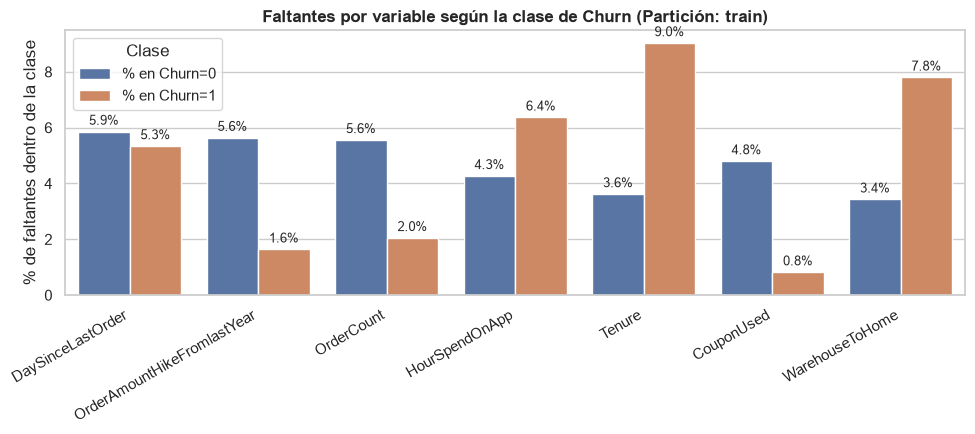

In [7]:
y = df[TARGET]
resumen_na = pd.DataFrame({
    "n_faltantes": df[cols_na].isna().sum(),
    "% faltante": (100 * df[cols_na].isna().mean()).round(2)
})
resumen_na["% en Churn=0"] = [round(100 * df.loc[y == 0, c].isna().mean(), 2) for c in resumen_na.index]
resumen_na["% en Churn=1"] = [round(100 * df.loc[y == 1, c].isna().mean(), 2) for c in resumen_na.index]
resumen_na = resumen_na.sort_values("% faltante", ascending=False)
display(resumen_na)
exportar(resumen_na, "02_faltantes_resumen")

n_na_fila = df[cols_na].isna().sum(axis=1)
tiene_na = n_na_fila > 0
print(f"Total de celdas faltantes en {EDA_SOBRE}: {int(n_na_fila.sum())}")
print(f"Filas con al menos un faltante: {int(tiene_na.sum())} ({tiene_na.mean():.2%}) | Filas completas: {int((~tiene_na).sum())}")
print(f"Distribución del número de NaNs por fila: {n_na_fila.value_counts().to_dict()}")

fig, ax = plt.subplots(figsize=(10, 4.5))
largo = resumen_na[["% en Churn=0", "% en Churn=1"]].reset_index().melt(
    id_vars="index", var_name="Clase", value_name="% faltante"
)
sns.barplot(data=largo, x="index", y="% faltante", hue="Clase", palette=[COLORES[0], COLORES[1]], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=9, padding=3)

ax.set_xlabel("")
ax.set_ylabel("% de faltantes dentro de la clase")
ax.set_title(f"Faltantes por variable según la clase de Churn (Partición: {EDA_SOBRE})", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

guardar(fig, "02_faltantes_por_clase")

plt.show()

A partir de estos resultados observamos que, de los 3.113 representantes de grupo usados en el EDA, **1.032 (33,15 %) presentan exactamente un valor faltante** y 2.081 tienen información completa; ningún registro presenta más de un dato faltante. También encontramos diferencias en la proporción de valores ausentes entre las clases de Churn, lo que justifica estudiar si estos patrones aportan información relevante para el modelado.


### 2.2 Asociación de la ausencia con `Churn`: chi-cuadrado, odds ratios y compensación de efectos

Acá revisamos si el hecho de que falte un dato se asocia con `Churn` usando tablas de contingencia, chi-cuadrado, *Odds Ratios* (con IC del 95 %) y el ajuste de Benjamini-Hochberg.

Después del ajuste, cinco variables muestran asociación estadísticamente significativa.
- **OR > 1:** Cuando falta `Tenure` o `WarehouseToHome`, se ve mayor proporción de abandono.
- **OR < 1:** Cuando falta `OrderCount`, `OrderAmountHikeFromlastYear` o `CouponUsed`, se ve menor proporción de abandono.

En `HourSpendOnApp` y `DaySinceLastOrder` no sale significativo tras el ajuste.

Ojo con leer esto como causa y efecto: más adelante vemos que los faltantes se concentran en ciertos tramos de `CashbackAmount`, así que estos *Odds Ratios* reflejan esas diferencias de bandas y no que "faltar el dato" provoque directamente el abandono.


,n_ausentes,churn_si_ausente_%,churn_si_presente_%,dif_pp,OR,IC95_inf,IC95_sup,chi2,p,q_BH,asociada_a_churn
variable,,,,,,,,,,,
Tenure,139,31.7,14.9,16.8,2.66,1.84,3.85,27.01,2.027898e-07,0.000001,SÍ
WarehouseToHome,128,29.7,15.0,14.6,2.40,1.62,3.55,18.85,1.410526e-05,0.000049,SÍ
HourSpendOnApp,143,21.7,15.4,6.3,1.54,1.03,2.32,3.67,5.539268e-02,0.064625,no
DaySinceLastOrder,180,14.4,15.7,-1.3,0.92,0.60,1.40,0.12,7.257758e-01,0.725776,no
OrderCount,156,6.4,16.1,-9.7,0.37,0.20,0.70,9.89,1.664508e-03,0.002330,SÍ
OrderAmountHikeFromlastYear,156,5.1,16.2,-11.1,0.30,0.15,0.59,12.94,3.223657e-04,0.000564,SÍ
CouponUsed,130,3.1,16.2,-13.1,0.18,0.07,0.47,15.26,9.381100e-05,0.000219,SÍ


=== DEMOSTRACIÓN DE LA COMPENSACIÓN DE EFECTOS A NIVEL DE FILA ===
• Tasa de Churn en clientes con 1 dato faltante: 15.60%
• Tasa de Churn en clientes sin datos faltantes: 15.67%
• Prueba Chi-cuadrado agregada: chi2 = 0.000, p = 1.000 (No significativa)
Conclusión técnica: Como la ausencia en 'WarehouseToHome'/'Tenure' se asocia a un mayor Churn (OR > 2.2)
 y en 'CouponUsed'/'OrderAmountHike'/'OrderCount' se asocia a una reducción (OR < 0.40), agregarlos en una sola bandera booleana ('tiene_na') compensa ambos efectos opuestos.
Por tanto, se recomienda usar indicadores de ausencia individuales por columna en lugar de una bandera global.



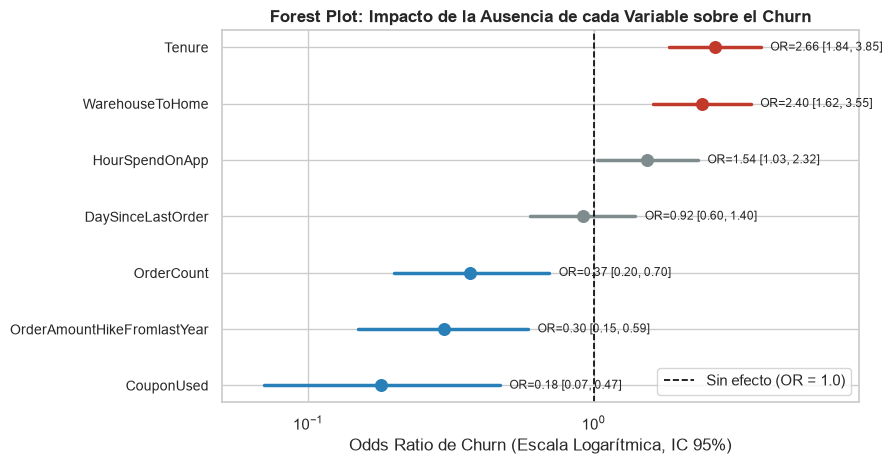

In [8]:
filas = []

for c in cols_na:
    m = df[c].isna()
    t = pd.crosstab(m, y).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    chi2, p = stats.chi2_contingency(t)[:2]
    a, b = t.loc[True, 1], t.loc[True, 0]
    cc, d = t.loc[False, 1], t.loc[False, 0]
    orr = ((a + 0.5) * (d + 0.5)) / ((b + 0.5) * (cc + 0.5))
    se = np.sqrt(1 / (a + 0.5) + 1 / (b + 0.5) + 1 / (cc + 0.5) + 1 / (d + 0.5))
    filas.append({
        "variable": c, "n_ausentes": int(a + b),
        "churn_si_ausente_%": round(100 * a / (a + b), 1),
        "churn_si_presente_%": round(100 * cc / (cc + d), 1),
        "dif_pp": round(100 * (a / (a + b) - cc / (cc + d)), 1),
        "OR": round(orr, 2),
        "IC95_inf": round(np.exp(np.log(orr) - 1.96 * se), 2),
        "IC95_sup": round(np.exp(np.log(orr) + 1.96 * se), 2),
        "chi2": round(chi2, 2), "p": p
    })

tabla_na_churn = pd.DataFrame(filas).set_index("variable")
tabla_na_churn["q_BH"] = bh(tabla_na_churn["p"].values)
tabla_na_churn["asociada_a_churn"] = np.where(tabla_na_churn["q_BH"] < ALPHA, "SÍ", "no")
tabla_na_churn = tabla_na_churn.sort_values("OR", ascending=False)
display(tabla_na_churn)
exportar(tabla_na_churn, "02_faltantes_vs_churn")

chi2_f, p_f = stats.chi2_contingency(pd.crosstab(tiene_na, y))[:2]
print("=== DEMOSTRACIÓN DE LA COMPENSACIÓN DE EFECTOS A NIVEL DE FILA ===")
print(f"• Tasa de Churn en clientes con 1 dato faltante: {100 * y[tiene_na].mean():.2f}%")
print(f"• Tasa de Churn en clientes sin datos faltantes: {100 * y[~tiene_na].mean():.2f}%")
print(f"• Prueba Chi-cuadrado agregada: chi2 = {chi2_f:.3f}, p = {p_f:.3f} (No significativa)")
print("Conclusión técnica: Como la ausencia en 'WarehouseToHome'/'Tenure' se asocia a un mayor Churn (OR > 2.2)\n y en 'CouponUsed'/'OrderAmountHike'/'OrderCount' se asocia a una reducción (OR < 0.40), agregarlos en una sola bandera booleana ('tiene_na') compensa ambos efectos opuestos.\nPor tanto, se recomienda usar indicadores de ausencia individuales por columna en lugar de una bandera global.\n")

fig, ax = plt.subplots(figsize=(9, 4.8))
y_pos = np.arange(len(tabla_na_churn))
ors = tabla_na_churn["OR"].values
ic_inf = tabla_na_churn["IC95_inf"].values
ic_sup = tabla_na_churn["IC95_sup"].values
colores_or = ["#c0392b" if (o > 1 and q < ALPHA) else ("#2980b9" if (o < 1 and q < ALPHA) else "#7f8c8d")
              for o, q in zip(ors, tabla_na_churn["q_BH"])]

for i in range(len(tabla_na_churn)):
    ax.plot([ic_inf[i], ic_sup[i]], [y_pos[i], y_pos[i]], color=colores_or[i], lw=2.5)
    ax.scatter(ors[i], y_pos[i], color=colores_or[i], s=70, zorder=3)
    ax.text(ic_sup[i] * 1.08, y_pos[i], f"OR={ors[i]:.2f} [{ic_inf[i]:.2f}, {ic_sup[i]:.2f}]", va="center", fontsize=8.5)

ax.axvline(1.0, color="black", linestyle="--", lw=1.2, label="Sin efecto (OR = 1.0)")
ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(tabla_na_churn.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0.05, 8.5)
ax.set_xlabel("Odds Ratio de Churn (Escala Logarítmica, IC 95%)")
ax.set_title("Forest Plot: Impacto de la Ausencia de cada Variable sobre el Churn", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
guardar(fig, "02_forest_plot_odds_ratio_faltantes")

plt.show()

### 2.3 Patrón estructural de ausencia: exclusión mutua por fila

Al inspeccionar la matriz de nulidad y la correlación $\phi$ entre indicadores binarios de ausencia, se verifica una propiedad estructural del dataset: **ningún registro presenta más de un valor faltante a la vez** (`n_na_fila` toma únicamente los valores $0$ o $1$). En consecuencia, los indicadores de ausencia tienen correlación ligeramente negativa constante ($\phi \approx -0.05$) entre todos los pares de variables.

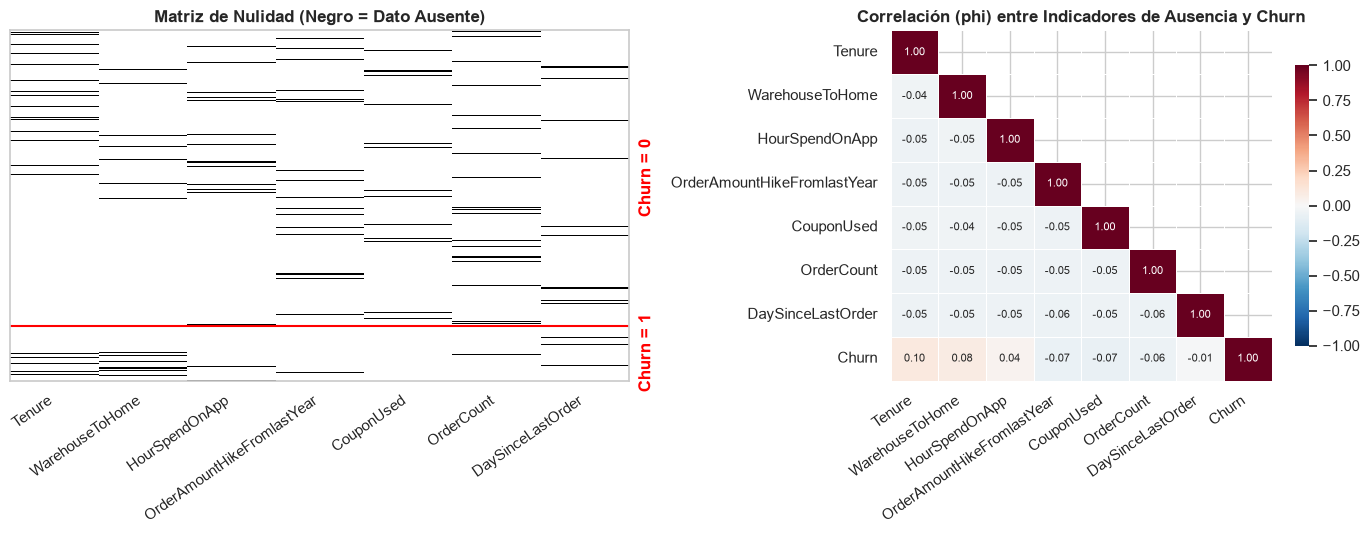

In [9]:
orden = df.sort_values(TARGET).index
M = df.loc[orden, cols_na].isna().values
n0 = int((y == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.imshow(M, aspect="auto", cmap="Greys", interpolation="nearest")
ax.grid(False)
ax.axhline(n0 - 0.5, color="red", lw=1.5)
ax.set_xticks(range(len(cols_na)))
ax.set_xticklabels(cols_na, rotation=35, ha="right")
ax.set_yticks([])
ax.text(len(cols_na) - 0.4, n0 / 2, "Churn = 0", rotation=90, va="center", color="red", fontweight="bold")
ax.text(len(cols_na) - 0.4, n0 + (len(df) - n0) / 2, "Churn = 1", rotation=90, va="center", color="red", fontweight="bold")
ax.set_title("Matriz de Nulidad (Negro = Dato Ausente)", fontweight="bold")

ind = df[cols_na].isna().astype(int)
ind_churn = ind.assign(Churn=y.values)
corr_na = ind_churn.corr()
sns.heatmap(
    corr_na, mask=np.triu(np.ones(corr_na.shape, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[1]
)
axes[1].set_title("Correlación (phi) entre Indicadores de Ausencia y Churn", fontweight="bold")
plt.setp(axes[1].get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
guardar(fig, "02_patron_de_ausencia")

plt.show()

En las gráficas se ve clarísimo que los faltantes no se mezclan en la misma fila: si falta un dato, no falta ningún otro. Que no haya "combos" de vacíos y que el patrón sea tan marcado ya nos hace sospechar que esto no pasó al azar, lo que nos lleva directo a revisar el mecanismo de ausencia en la siguiente sección.


### 2.4 Diagnóstico del mecanismo de ausencia (MCAR vs. MAR)

Para ver si la ausencia depende de otras variables observadas (**MAR**, *Missing At Random*), entrenamos un `HistGradientBoostingClassifier` con validación cruzada estratificada de 5 pliegues para predecir `df[c].isna()` usando **solo variables 100 % completas** (`columnas_completas`), así evitamos meter información tramposa de otras columnas con nulos o indicadores de ausencia:

- **ROC-AUC cerca de 0.50:** Básicamente no hay señal para predecir la ausencia desde las variables completas.
- **ROC-AUC bien por encima de 0.50:** Sí se puede predecir la ausencia con variables observadas; esto es compatible con un patrón MAR, aunque no confirma por sí solo el mecanismo exacto.
- **Cambio al sumar Churn:** Sirve para ver si saber si hubo abandono ayuda a predecir el nulo.

In [10]:
columnas_completas = [c for c in df.columns if c != TARGET and not df[c].isna().any()]
assert not df[columnas_completas].isna().any().any(), "Error: Existen nulos en columnas_completas"

print(f"Predictores 100% completos utilizados ({len(columnas_completas)}): {columnas_completas}\n")

Xd_completas = pd.get_dummies(
    df[columnas_completas],
    columns=[c for c in nom_cols if c in columnas_completas],
    dtype=float
)

cv_mar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

mdl_mar = HistGradientBoostingClassifier(max_depth=3, min_samples_leaf=30, max_iter=100, random_state=SEED)

filas_mar = []
for c in cols_na:
    t_na = df[c].isna().astype(int)
    X_sin = Xd_completas.copy()
    X_con = X_sin.assign(Churn=y.values)

    auc_sin = cross_validate(mdl_mar, X_sin, t_na, cv=cv_mar, scoring="roc_auc")["test_score"].mean()
    auc_con = cross_validate(mdl_mar, X_con, t_na, cv=cv_mar, scoring="roc_auc")["test_score"].mean()

    filas_mar.append({
        "variable": c,
        "AUC sin Churn (MAR)": round(auc_sin, 3),
        "AUC con Churn": round(auc_con, 3),
        "Delta AUC (Churn)": round(auc_con - auc_sin, 3),
        "Patrón observado": (
        "Alta dependencia de variables observadas"
        if auc_sin >= 0.70
        else "Dependencia moderada de variables observadas"
        if auc_sin >= 0.58
        else "Sin evidencia clara de dependencia"
      )
    })

mar_tabla = pd.DataFrame(filas_mar).set_index("variable").sort_values("AUC sin Churn (MAR)", ascending=False)
display(mar_tabla)
exportar(mar_tabla, "02_diagnostico_mecanismo_mar")

print("\n=== ANÁLISIS DE BLOQUES POR CASHBACKAMOUNT ===")

filas = []

for c in cols_na:
    m = df[c].isna()
    lo, hi = df.loc[m, "CashbackAmount"].agg(["min", "max"])
    banda = df["CashbackAmount"].between(lo, hi)
    filas.append({"variable": c, "cashback_min": lo, "cashback_max": hi,
                  "filas_en_banda": int(banda.sum()), "NaN_en_banda": int((m & banda).sum()),
                  "churn_banda_%": round(100 * y[banda].mean(), 1)})

display(pd.DataFrame(filas).set_index("variable").sort_values("cashback_min"))

Predictores 100% completos utilizados (11): ['PreferredLoginDevice', 'CityTier', 'PreferredPaymentMode', 'Gender', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'CashbackAmount']



,AUC sin Churn (MAR),AUC con Churn,Delta AUC (Churn),Patrón observado
variable,,,,
Tenure,1.000,1.000,0.0,Alta dependencia de variables observadas
WarehouseToHome,1.000,1.000,0.0,Alta dependencia de variables observadas
HourSpendOnApp,1.000,1.000,0.0,Alta dependencia de variables observadas
CouponUsed,1.000,1.000,0.0,Alta dependencia de variables observadas
OrderCount,1.000,1.000,0.0,Alta dependencia de variables observadas
DaySinceLastOrder,1.000,1.000,0.0,Alta dependencia de variables observadas
OrderAmountHikeFromlastYear,0.999,0.999,-0.0,Alta dependencia de variables observadas



=== ANÁLISIS DE BLOQUES POR CASHBACKAMOUNT ===


,cashback_min,cashback_max,filas_en_banda,NaN_en_banda,churn_banda_%
variable,,,,,
Tenure,112.00,123.13,140,139,32.1
WarehouseToHome,123.18,126.57,128,128,29.7
HourSpendOnApp,126.62,131.62,144,143,21.5
DaySinceLastOrder,209.34,231.42,180,180,14.4
OrderCount,231.73,260.70,156,156,6.4
CouponUsed,260.91,291.90,130,130,3.1
OrderAmountHikeFromlastYear,292.02,323.33,157,156,5.1



Los resultados muestran un patrón estructurado de datos faltantes asociado a CashbackAmount. Al analizar los rangos de esta variable, encontramos que prácticamente todos los registros ubicados en dichos segmentos presentan ausencia en una característica específica. Esto explica el AUC de 1,000 obtenido al predecir los indicadores de ausencia utilizando las variables observadas.

El comportamiento encontrado es compatible con un mecanismo MAR, ya que la ausencia puede explicarse mediante una variable observada: CashbackAmount. No obstante, no contamos con información adicional sobre el proceso original de generación de los datos para determinar cómo se produjo este patrón.

Este hallazgo también permite interpretar correctamente los Odds Ratios anteriores: reflejan diferencias entre los rangos de CashbackAmount y no un efecto directo de los valores faltantes sobre Churn. Además, como dentro de esos rangos existen pocos valores observados, la imputación representa una estimación con información limitada. Por esta razón consideramos importante conservar indicadores individuales de ausencia durante el modelado.

### 2.5 Concentración de faltantes por segmentos categóricos

Evaluamos la intensidad de asociación (V de Cramér corregida) entre el indicador de ausencia de cada variable y las variables categóricas/ordinales de segmentación (nominales, ordinales y binaria).

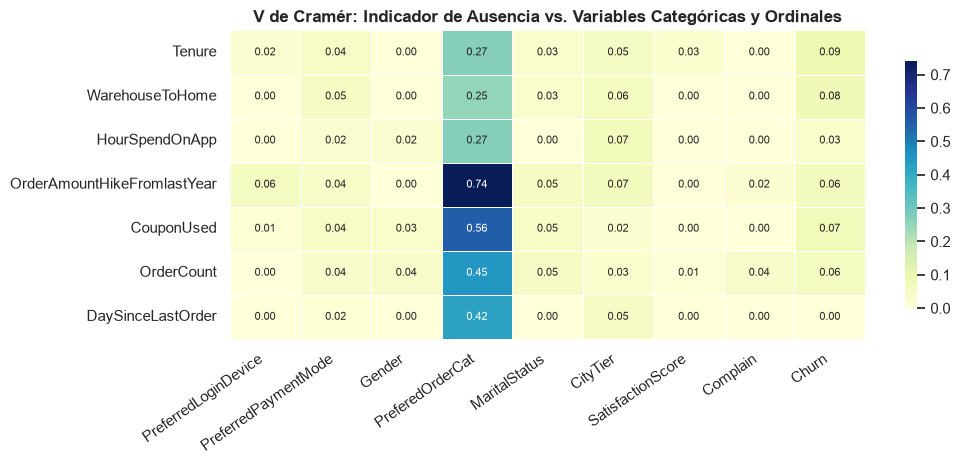

,variable_faltante,segmento,n,% faltante,% base,lift,p,q_BH
0,OrderAmountHikeFromlastYear,PreferedOrderCat = Others,150,72.67,5.01,14.50,2.885201e-106,5.856958e-104
1,CouponUsed,PreferedOrderCat = Grocery,223,40.81,4.18,9.77,1.951378e-64,1.980649e-62
2,DaySinceLastOrder,PreferedOrderCat = Fashion,486,28.60,5.78,4.95,9.135708e-57,6.181829e-55
3,OrderCount,PreferedOrderCat = Grocery,223,31.84,5.01,6.35,5.055811e-37,2.565824e-35
4,DaySinceLastOrder,PreferedOrderCat = Mobile Phone,1131,0.00,5.78,0.00,1.231490e-29,4.999848e-28
5,OrderCount,PreferedOrderCat = Mobile Phone,1131,0.00,5.01,0.00,8.763492e-26,2.541413e-24
6,OrderAmountHikeFromlastYear,PreferedOrderCat = Mobile Phone,1131,0.00,5.01,0.00,8.763492e-26,2.541413e-24
7,OrderAmountHikeFromlastYear,PreferedOrderCat = Laptop & Accessory,1123,0.00,5.01,0.00,2.131571e-25,4.807876e-24
8,OrderCount,PreferedOrderCat = Laptop & Accessory,1123,0.00,5.01,0.00,2.131571e-25,4.807876e-24
9,Tenure,PreferedOrderCat = Mobile Phone,1131,11.94,4.47,2.67,2.079418e-24,4.221218e-23


Segmentos estadísticamente significativos (q_BH < 0.05): 51 de 203 evaluados (25.1%)


In [11]:
seg_vars = nom_cols + ord_cols + bin_cols + [TARGET]

V_na = pd.DataFrame(index=cols_na, columns=seg_vars, dtype=float)
for c in cols_na:
    for g in seg_vars:
        if c == g:
            V_na.loc[c, g] = np.nan
        else:
            V_na.loc[c, g] = cramers_v(ind[c], df[g])

fig, ax = plt.subplots(figsize=(10.5, 4.8))
sns.heatmap(
    V_na, cmap="YlGnBu", vmin=0, vmax=max(0.1, float(np.nanmax(V_na.values))),
    annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("V de Cramér: Indicador de Ausencia vs. Variables Categóricas y Ordinales", fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
guardar(fig, "02_V_ausencia_vs_categoricas")
plt.show()

filas_seg = []
for c in cols_na:
    m = df[c].isna()
    base = m.mean()
    for g in seg_vars:
        if c == g:
            continue
        for cat, sub in df.groupby(g, dropna=True):
            n = len(sub)
            k = int(m.loc[sub.index].sum())
            if n >= 80 and base > 0:
                filas_seg.append({
                    "variable_faltante": c, "segmento": f"{g} = {cat}", "n": n,
                    "% faltante": round(100 * k / n, 2), "% base": round(100 * base, 2),
                    "lift": round((k / n) / base, 2), "p": stats.binomtest(k, n, base).pvalue
                })

seg_df = pd.DataFrame(filas_seg)
seg_df["q_BH"] = bh(seg_df["p"].values)
n_sig_seg = int((seg_df["q_BH"] < ALPHA).sum())
total_seg = len(seg_df)

display(seg_df.sort_values("p").head(12).reset_index(drop=True))
print(f"Segmentos estadísticamente significativos (q_BH < {ALPHA}): {n_sig_seg} de {total_seg} evaluados ({n_sig_seg/total_seg:.1%})")
exportar(seg_df.sort_values("p"), "02_faltantes_segmentos")

A partir de este análisis cruzado, evaluamos si la falta de información se concentra de manera inusual en ciertos perfiles o grupos de clientes (por ejemplo, si faltan más datos en quienes compran en cierta categoría o pagan con un método específico). Gracias a las pruebas estadísticas y al mapa de calor, podemos identificar estas relaciones. Sin embargo, conectando esto con el hallazgo de la celda anterior, cualquier asociación fuerte que detectemos aquí (como podría ser con la categoría de compra PreferedOrderCat) es en realidad un "espejo" o efecto secundario (proxy) de los bloques de CashbackAmount. Es decir, la información falta por los rangos de dinero devuelto, y esos rangos coinciden casualmente con ciertas categorías de clientes.

## 3. Análisis univariado integral (continuas, discretas y categóricas)

Se analizan **todas** las variables predictoras agrupadas según su naturaleza:
1. **Variables Continuas (`cont_cols`):** Estadísticos descriptivos, asimetría, curtosis, detección de *outliers* e inspección de distribuciones (Histogramas de densidad, Boxplots y Curvas ECDF por clase de `Churn`).
2. **Variables Discretas de Conteo (`disc_cols`):** `NumberOfAddress`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount`, `HourSpendOnApp` y `NumberOfDeviceRegistered`, evaluando su distribución y tasa de abandono condicional.
3. **Variables Categóricas, Ordinales y Binarias (`cat_vars`):** Tasas de `Churn` por categoría frente a la tasa base de entrenamiento.

In [12]:
print("=== 3.1 ESTADÍSTICOS DESCRIPTIVOS: VARIABLES NUMÉRICAS (CONTINUAS Y DISCRETAS DE CONTEO) ===")
desc = df[num_cols].describe(percentiles=[0.25, 0.50, 0.75]).T
desc["tipo"] = ["Continua" if c in cont_cols else "Discreta (Conteo)" for c in desc.index]
desc["asimetría"] = df[num_cols].skew()
desc["curtosis"] = df[num_cols].kurt()
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
desc["outliers_IQR"] = ((df[num_cols] < (q1 - 1.5 * iqr)) | (df[num_cols] > (q3 + 1.5 * iqr))).sum()
desc["% outliers"] = (100 * desc["outliers_IQR"] / desc["count"]).round(2)

cols_orden_desc = ["tipo", "count", "mean", "std", "min", "25%", "50%", "75%", "max", "asimetría", "curtosis", "outliers_IQR", "% outliers"]
desc = desc[cols_orden_desc]
display(desc.round(2))
exportar(desc.round(3), "03_univariado_numericas_completo")

print("\n=== AUDITORÍA DE EXTREMOS DE DOMINIO (VALORES ATÍPICOS PUNTUALES) ===")
print(f"• Tenure > 31 meses: {int((df['Tenure'] > 31).sum())} registros (valores observados: {sorted(df.loc[df['Tenure'] > 31, 'Tenure'].dropna().unique())})")
print(f"• WarehouseToHome > 40 km: {int((df['WarehouseToHome'] > 40).sum())} registros (valores observados: {sorted(df.loc[df['WarehouseToHome'] > 40, 'WarehouseToHome'].dropna().unique())})")
print(f"• NumberOfAddress > 11 direcciones: {int((df['NumberOfAddress'] > 11).sum())} registros (valores observados: {sorted(df.loc[df['NumberOfAddress'] > 11, 'NumberOfAddress'].dropna().unique())})")

=== 3.1 ESTADÍSTICOS DESCRIPTIVOS: VARIABLES NUMÉRICAS (CONTINUAS Y DISCRETAS DE CONTEO) ===


,tipo,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis,outliers_IQR,% outliers
Tenure,Continua,2974.0,10.28,8.65,0.0,2.00,9.00,16.00,51.00,0.70,-0.32,2,0.07
WarehouseToHome,Continua,2985.0,15.38,8.78,5.0,9.00,13.00,20.00,127.00,2.12,16.38,2,0.07
DaySinceLastOrder,Continua,2933.0,4.58,3.66,0.0,2.00,3.00,8.00,46.00,1.36,6.33,7,0.24
CashbackAmount,Continua,3113.0,178.12,49.31,0.0,146.33,164.39,198.88,324.99,1.11,0.93,231,7.42
NumberOfAddress,Discreta (Conteo),3113.0,4.19,2.62,1.0,2.00,3.00,6.00,22.00,1.21,1.71,4,0.13
OrderAmountHikeFromlastYear,Discreta (Conteo),2957.0,15.65,3.67,11.0,13.00,15.00,18.00,26.00,0.81,-0.26,16,0.54
CouponUsed,Discreta (Conteo),2983.0,1.84,1.99,0.0,1.00,1.00,2.00,16.00,2.54,9.03,383,12.84
OrderCount,Discreta (Conteo),2957.0,3.12,3.00,1.0,1.00,2.00,3.00,16.00,2.06,4.01,420,14.20
HourSpendOnApp,Discreta (Conteo),2970.0,2.93,0.72,0.0,2.00,3.00,3.00,5.00,-0.01,-0.70,3,0.10
NumberOfDeviceRegistered,Discreta (Conteo),3113.0,3.68,1.04,1.0,3.00,4.00,4.00,6.00,-0.38,0.46,221,7.10



=== AUDITORÍA DE EXTREMOS DE DOMINIO (VALORES ATÍPICOS PUNTUALES) ===
• Tenure > 31 meses: 2 registros (valores observados: [np.float64(50.0), np.float64(51.0)])
• WarehouseToHome > 40 km: 2 registros (valores observados: [np.float64(126.0), np.float64(127.0)])
• NumberOfAddress > 11 direcciones: 4 registros (valores observados: [np.int64(19), np.int64(20), np.int64(21), np.int64(22)])


De esta tabla estadística extraemos el panorama general de cómo se distribuyen nuestras variables numéricas. Al observar medidas como la media, la mediana (cuartil 50%) y la asimetría, podemos saber si los datos están balanceados o si tienden a acumularse hacia un lado de la gráfica. El punto más importante aquí es la detección de outliers (valores atípicos), los cuales nos muestran registros extremos, como clientes que viven a más de 40 kilómetros de distancia o tienen más de 11 direcciones registradas. Identificar esto es fundamental, ya que modelos predictivos como la Regresión Logística o las Máquinas de Vectores de Soporte (SVM) son sensibles a estos valores inusuales y podrían sesgarse si no aplicamos un tratamiento adecuado durante el preprocesamiento, como el escalado o la estandarización.


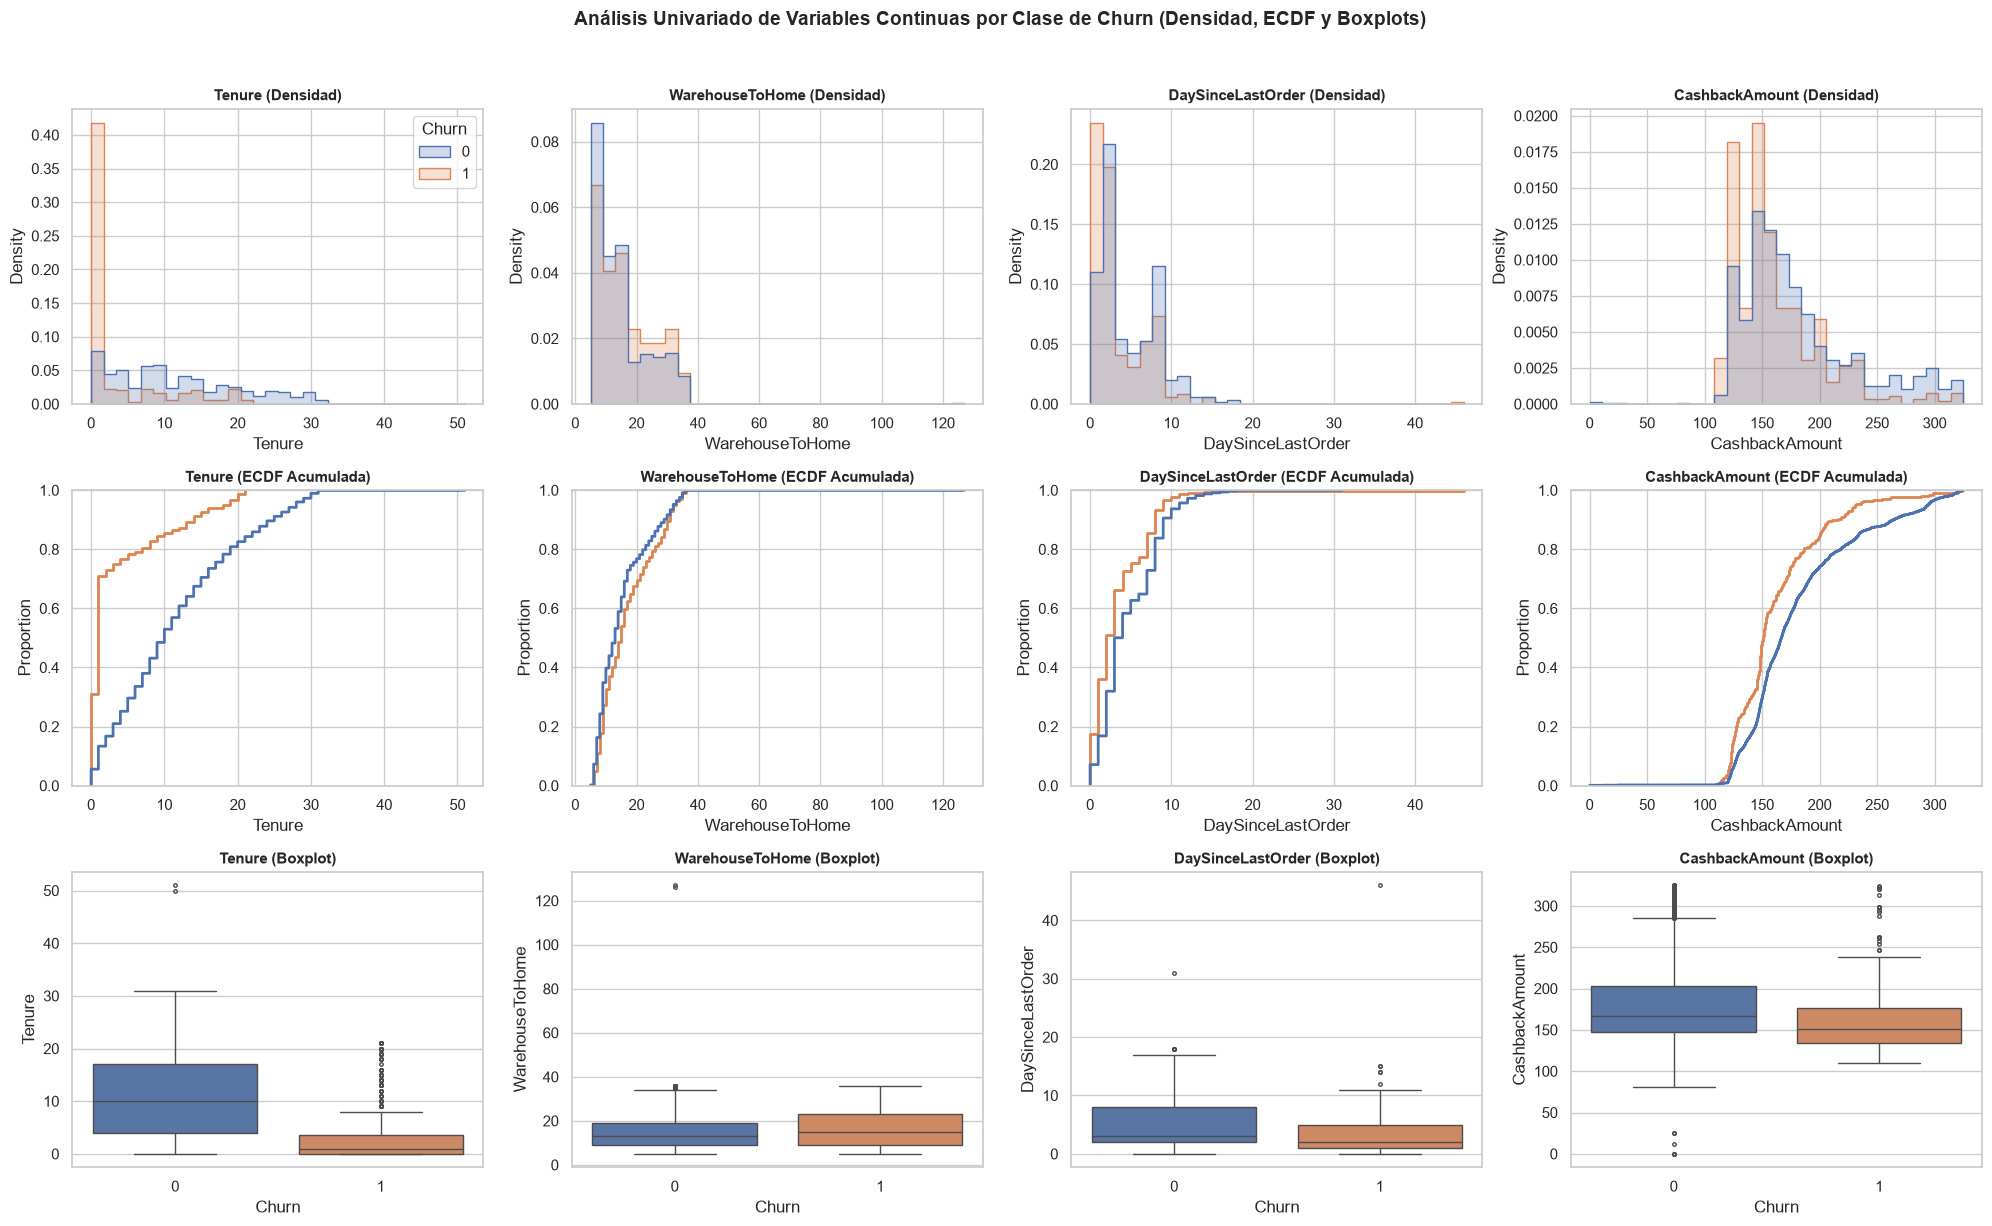

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))

for idx, c in enumerate(cont_cols):
    ax_h = axes[0, idx]
    sns.histplot(
        data=df, x=c, hue=TARGET, stat="density", common_norm=False, element="step",
        bins=30, palette=COLORES, ax=ax_h, legend=(idx == 0)
    )
    ax_h.set_title(f"{c} (Densidad)", fontsize=11, fontweight="bold")

    ax_e = axes[1, idx]
    sns.ecdfplot(data=df, x=c, hue=TARGET, palette=COLORES, lw=2, ax=ax_e, legend=False)
    ax_e.set_title(f"{c} (ECDF Acumulada)", fontsize=11, fontweight="bold")

    ax_b = axes[2, idx]
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, palette=COLORES, legend=False, ax=ax_b, fliersize=2.5)
    ax_b.set_title(f"{c} (Boxplot)", fontsize=11, fontweight="bold")
    ax_b.set_xlabel("Churn")

fig.suptitle("Análisis Univariado de Variables Continuas por Clase de Churn (Densidad, ECDF y Boxplots)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "03_continuas_densidad_ecdf_boxplots")
plt.show()

A partir de estas tres gráficas podemos entender el comportamiento profundo de cada variable continua y su relación con la fuga de clientes (Churn). Los histogramas nos muestran la "forma" de los datos y dónde se concentran; las curvas acumuladas (ECDF) nos permiten comparar de forma muy limpia, y sin los sesgos visuales que a veces causan las barras tradicionales, si un grupo de clientes tiende a tener valores más altos o más bajos que el otro. Finalmente, los diagramas de caja (boxplots) nos dan un resumen rápido para comparar las medianas y visualizar de inmediato qué tantos valores extremos (outliers) tiene cada grupo. En conjunto, esto nos indica visualmente qué variables tienen un poder predictivo claro para separar a los clientes que se quedan de los que se van, preparándonos para los algoritmos de clasificación de la siguiente etapa.

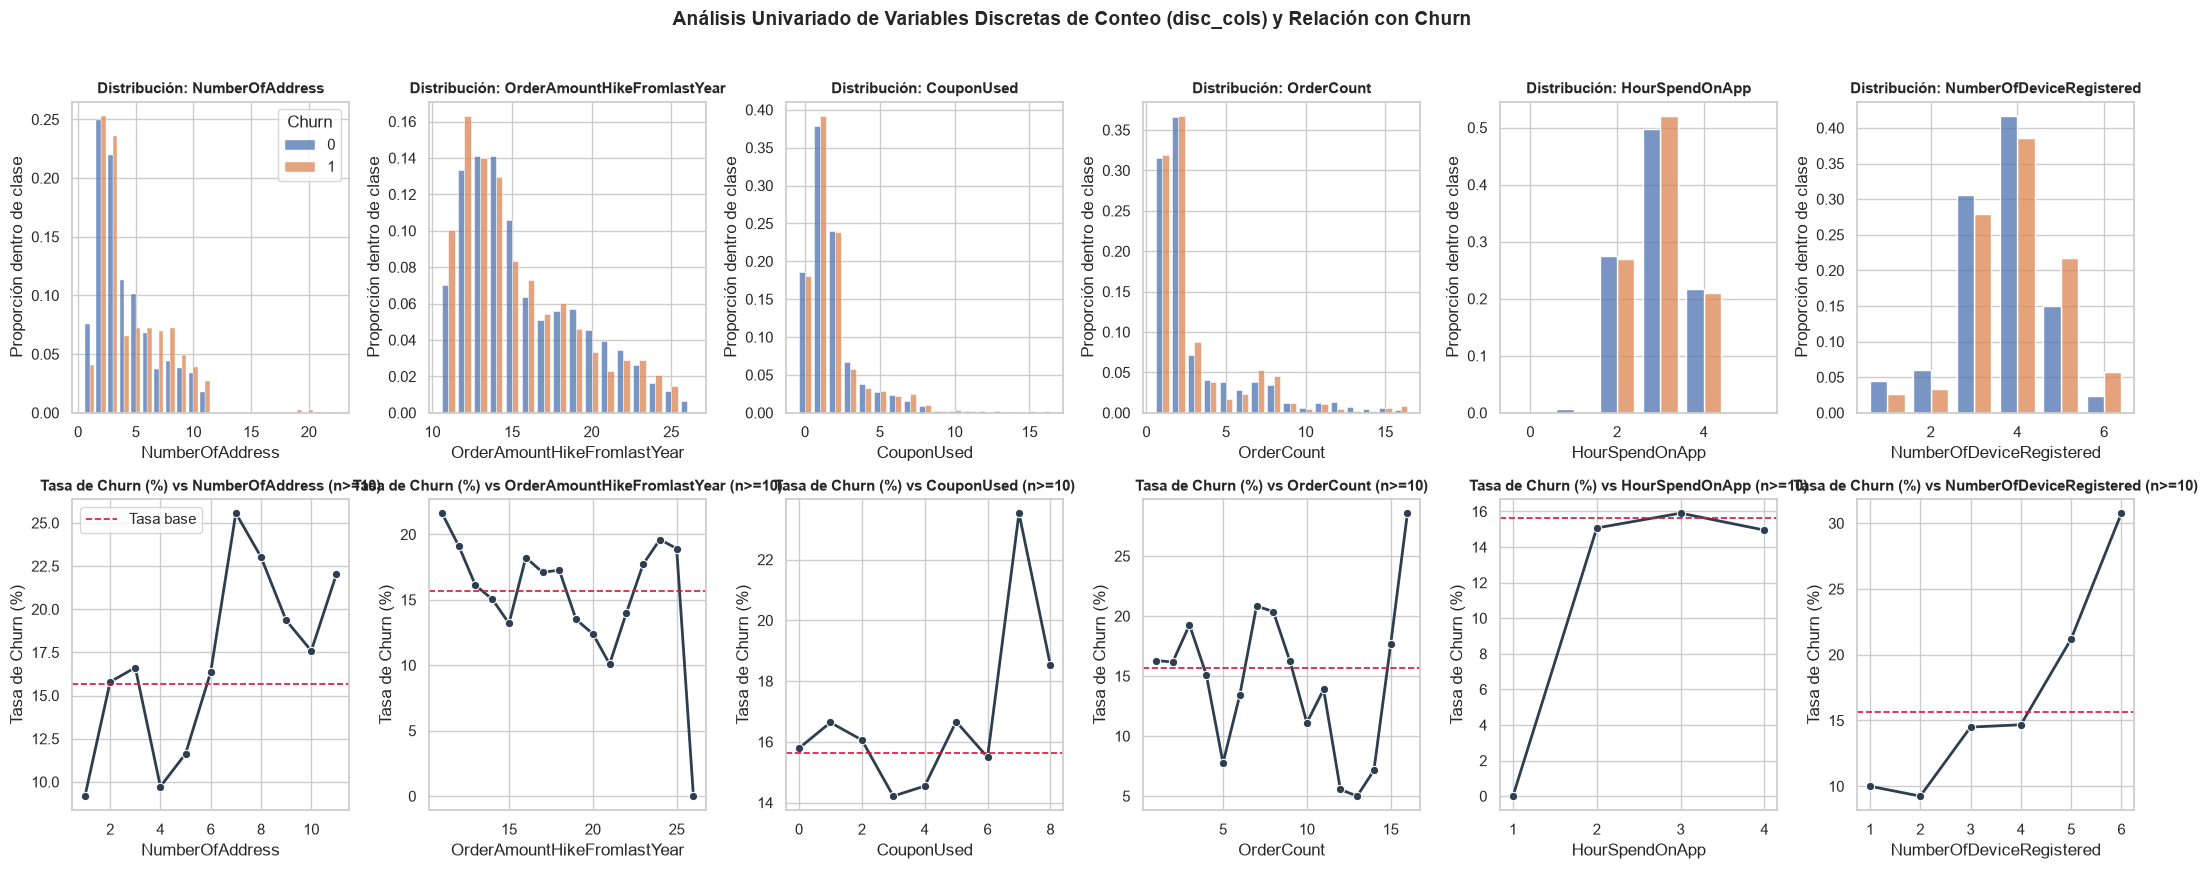

In [14]:
fig, axes = plt.subplots(2, len(disc_cols), figsize=(3.6 * len(disc_cols), 8.5))

for idx, c in enumerate(disc_cols):
    ax_top = axes[0, idx]
    sns.histplot(
        data=df, x=c, hue=TARGET, stat="probability", common_norm=False,
        discrete=True, element="bars", multiple="dodge", shrink=0.8, palette=COLORES, ax=ax_top, legend=(idx == 0)
    )
    ax_top.set_title(f"Distribución: {c}", fontsize=11, fontweight="bold")
    ax_top.set_ylabel("Proporción dentro de clase")

    ax_bot = axes[1, idx]
    t_disc = df.groupby(c, dropna=True)[TARGET].agg(n="size", tasa="mean").reset_index()
    t_disc["tasa"] *= 100
    t_disc_f = t_disc[t_disc["n"] >= 10]
    sns.lineplot(data=t_disc_f, x=c, y="tasa", marker="o", color="#2c3e50", lw=2, ax=ax_bot)
    ax_bot.axhline(100 * y.mean(), color="crimson", ls="--", lw=1.2, label="Tasa base")
    ax_bot.set_title(f"Tasa de Churn (%) vs {c} (n>=10)", fontsize=11, fontweight="bold")
    ax_bot.set_ylabel("Tasa de Churn (%)")
    if idx == 0:
        ax_bot.legend()

fig.suptitle("Análisis Univariado de Variables Discretas de Conteo (disc_cols) y Relación con Churn", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "03_discretas_distribucion_y_churn")
plt.show()

Con estas gráficas evaluamos el comportamiento de las variables que se miden en cantidades enteras (como el número de direcciones o los cupones usados). La fila superior nos permite ver cómo se distribuyen estas cantidades comparando a los clientes que se van frente a los que se quedan. La fila inferior es aún más directa: nos dibuja una línea de tendencia que muestra cómo sube o baja la probabilidad exacta de abandono a medida que aumenta la cantidad de la variable, comparándola siempre contra la "tasa base" (el promedio general de abandono). Esto es vital para identificar patrones; por ejemplo, si a partir del tercer cupón usado la probabilidad de irse cae por debajo del promedio, ya tenemos un indicio fuerte de retención que los modelos de Machine Learning podrán aprovechar.


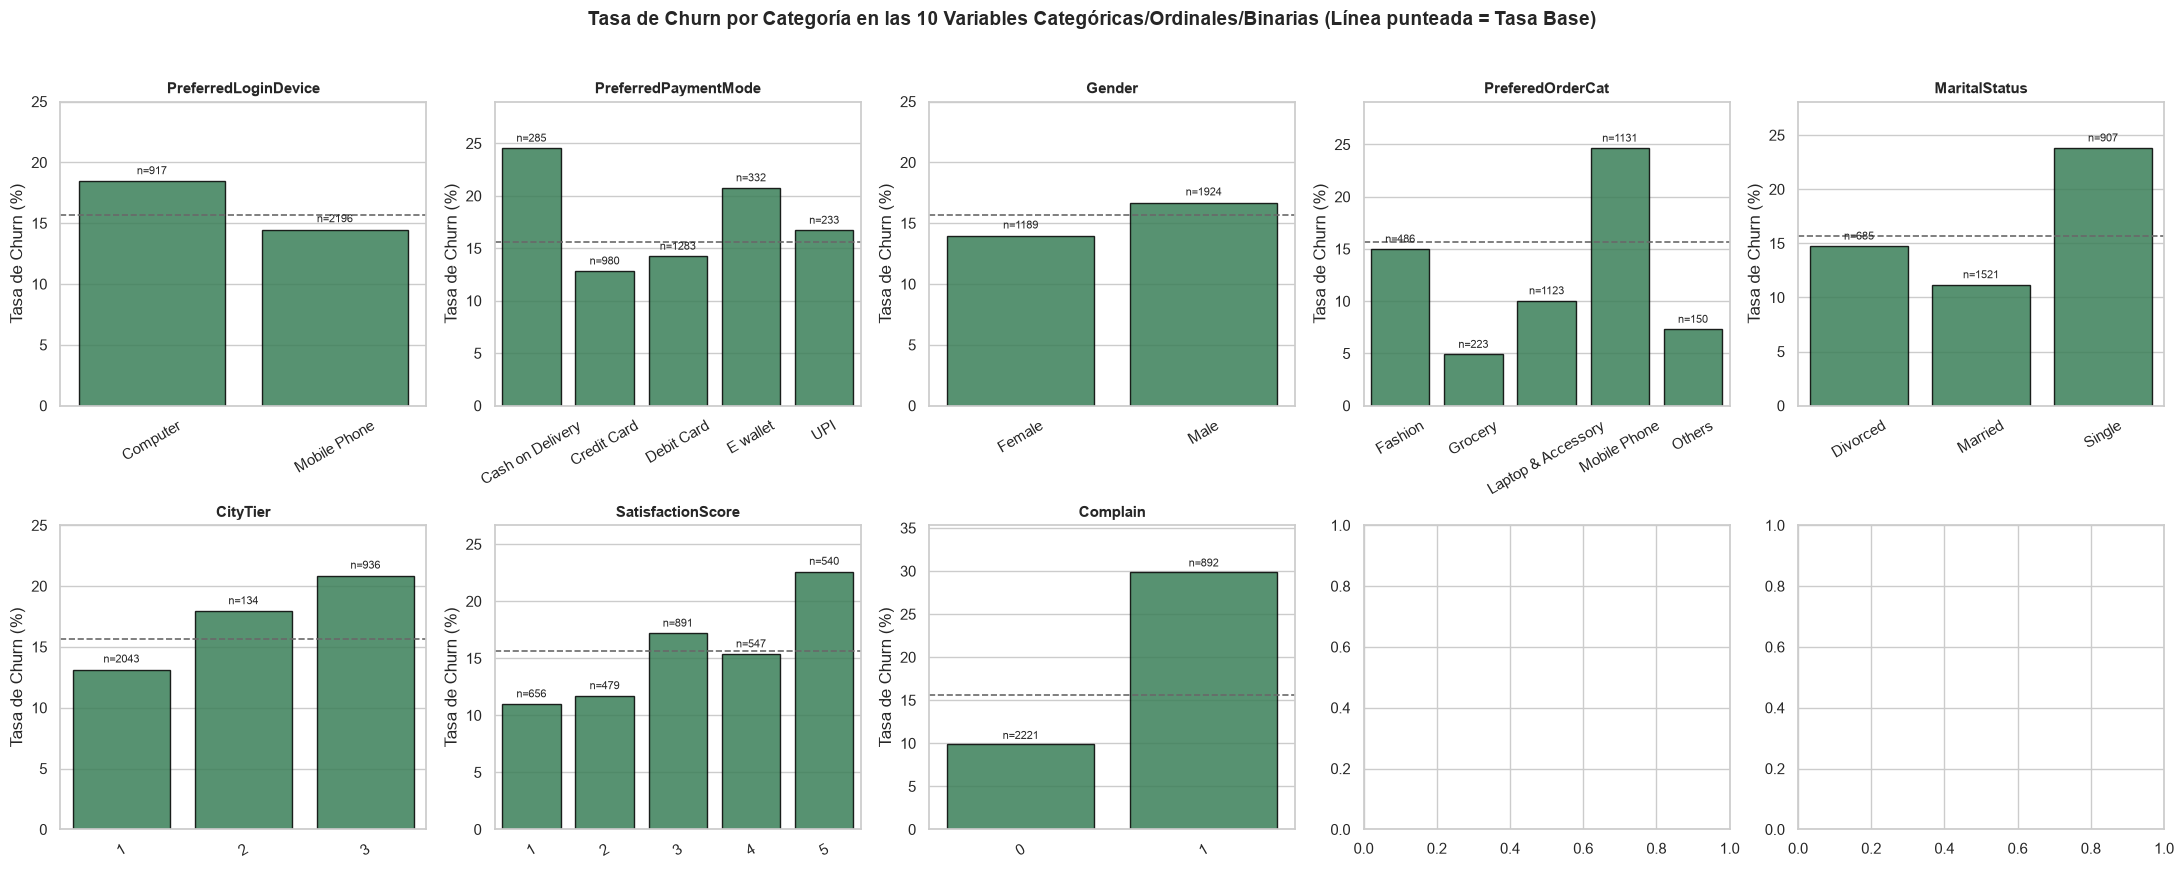

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))

for ax, g in zip(axes.ravel(), cat_vars):
    t = df.groupby(g, dropna=True)[TARGET].agg(["size", "mean"]).reset_index()
    t["mean"] *= 100
    sns.barplot(data=t, x=g, y="mean", color="seagreen", edgecolor="black", alpha=0.85, ax=ax)
    ax.axhline(100 * y.mean(), color="dimgray", ls="--", lw=1.2)
    for i, (n, v) in enumerate(zip(t["size"], t["mean"])):
        ax.text(i, v + 0.6, f"n={n}", ha="center", fontsize=8)
    ax.set_ylabel("Tasa de Churn (%)")
    ax.set_xlabel("")
    ax.set_title(g, fontsize=11, fontweight="bold")
    ax.set_ylim(0, max(t["mean"].max() * 1.18, 25))
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Tasa de Churn por Categoría en las 10 Variables Categóricas/Ordinales/Binarias (Línea punteada = Tasa Base)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
guardar(fig, "03_churn_por_categoria_completo")

plt.show()

Estas gráficas de barras nos permiten comparar el riesgo de abandono entre los distintos perfiles de clientes, divididos por sus características cualitativas (como su método de pago preferido, género o nivel de satisfacción). La altura de cada barra nos indica exactamente qué porcentaje de clientes en esa categoría abandonó la empresa, y la línea punteada nos sirve como ancla visual para identificar rápidamente qué grupos superan la tasa promedio y cuáles son más leales. Además, colocar la cantidad de clientes (n=) encima de cada barra es clave para evitar sacar conclusiones engañosas en categorías que tengan muy pocas personas, lo cual nos ayuda a seleccionar las características más confiables para entrenar los modelos.


## 4. Asociación global de cada variable predictora con `Churn`

Evaluamos las **18 variables predictoras** frente a `Churn`:
- **Categóricas, Ordinales y Binarias (`cat_vars`):** Prueba $\chi^2$ de independencia y tamaño del efecto mediante **V de Cramér corregida**.
- **Numéricas Continuas y Discretas de Conteo (`num_cols`):** Prueba no paramétrica $U$ de **Mann-Whitney** y tamaño del efecto mediante **correlación biserial por rangos** ($r_{rb} = \frac{2U}{n_1 n_0} - 1 \in [-1, 1]$).
- Todos los valores $p$ se ajustan por comparaciones múltiples con **Benjamini-Hochberg ($q_{BH}$)**.

In [16]:
filas_assoc = []
for g in cat_vars:
    t = pd.crosstab(df[g], y)
    chi2, p = stats.chi2_contingency(t)[:2]
    tasas = df.groupby(g)[TARGET].mean()
    filas_assoc.append({
        "variable": g, "naturaleza": "Categórica/Ordinal", "estadístico": round(chi2, 1), "p": p,
        "tamaño_efecto": round(cramers_v(df[g], y), 3),
        "detalle": f"rango de tasas: {100 * tasas.min():.1f}% a {100 * tasas.max():.1f}%"
    })

for c in num_cols:
    a = df.loc[y == 1, c].dropna()
    b = df.loc[y == 0, c].dropna()
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 2 * U / (len(a) * len(b)) - 1
    tipo_lbl = "Continua" if c in cont_cols else "Discreta (Conteo)"
    filas_assoc.append({
        "variable": c, "naturaleza": tipo_lbl, "estadístico": round(U, 0), "p": p,
        "tamaño_efecto": round(r_rb, 3),
        "detalle": f"mediana churn=1: {a.median():.1f} | churn=0: {b.median():.1f}"
    })

assoc = pd.DataFrame(filas_assoc).set_index("variable")
assoc["q_BH"] = bh(assoc["p"].values)
assoc["abs_efecto"] = assoc["tamaño_efecto"].abs()
assoc = assoc.sort_values("abs_efecto", ascending=False).drop(columns=["abs_efecto"])

display(assoc)

exportar(assoc, "04_asociacion_todas_variables_con_churn")

,naturaleza,estadístico,p,tamaño_efecto,detalle,q_BH
variable,,,,,,
Tenure,Continua,218060.0,3.819196e-94,-0.611,mediana churn=1: 1.0 | churn=0: 10.0,6.874552e-93
DaySinceLastOrder,Continua,421122.0,3.031737e-19,-0.261,mediana churn=1: 2.0 | churn=0: 3.0,1.364282e-18
CashbackAmount,Continua,477284.0,5.546534e-19,-0.254,mediana churn=1: 151.0 | churn=0: 166.7,1.996752e-18
Complain,Categórica/Ordinal,191.9,1.217021e-43,0.249,rango de tasas: 9.9% a 29.9%,1.095319e-42
PreferedOrderCat,Categórica/Ordinal,123.7,8.695545e-26,0.196,rango de tasas: 4.9% a 24.7%,5.217327e-25
MaritalStatus,Categórica/Ordinal,69.3,8.927468e-16,0.147,rango de tasas: 11.2% a 23.8%,2.678240e-15
NumberOfDeviceRegistered,Discreta (Conteo),724160.0,9.266945e-07,0.133,mediana churn=1: 4.0 | churn=0: 4.0,1.853389e-06
WarehouseToHome,Continua,639674.0,2.837040e-05,0.124,mediana churn=1: 15.0 | churn=0: 13.0,4.642429e-05
SatisfactionScore,Categórica/Ordinal,37.9,1.190533e-07,0.104,rango de tasas: 11.0% a 22.6%,3.061370e-07


En esta sección calculamos qué tan fuerte es la relación matemática entre cada variable y el abandono del cliente (Churn). Debido a que tenemos diferentes tipos de datos (como categorías de texto por un lado y números continuos por el otro), usamos dos pruebas estadísticas distintas para poder medir el impacto de todo en una escala unificada (el "tamaño del efecto"). Al ordenar los resultados, obtenemos un ranking objetivo de las características más importantes. Esta lista es fundamental para la etapa de reducción de dimensionalidad que nos exige el proyecto, ya que nos brinda el criterio base para decidir cuáles variables aportan información clave para los modelos predictivos y cuáles podríamos eliminar por ser estadísticamente irrelevantes.


## 5. Matrices de correlación y asociación por tipología

Se construyen las matrices de asociación empleando el estimador apropiado para cada combinación de escalas de medición, **incluyendo tanto las variables continuas como las discretas de conteo**:

| Subsección | Conjunto de Variables | Estimador Estadístico |
| :--- | :--- | :--- |
| **5.1** | Numéricas (`cont_cols + disc_cols`) | Correlación lineal de **Pearson ($r$)** |
| **5.2** | Numéricas (`cont_cols + disc_cols`) | Correlación monotónica de **Spearman ($\rho$)** y **VIF** |
| **5.3** | Categóricas + Ordinales + `Complain` + `Churn` | **V de Cramér corregida** (Simétrica) |
| **5.4** | Categóricas + Ordinales + `Complain` + `Churn` | **U de Theil** (Entropía condicional asimétrica) |
| **5.5** | Categóricas/Ordinales (filas) $\times$ Numéricas (columnas) | **Razón de correlación $\eta$ (Eta)** y análisis de dependencia estructural |

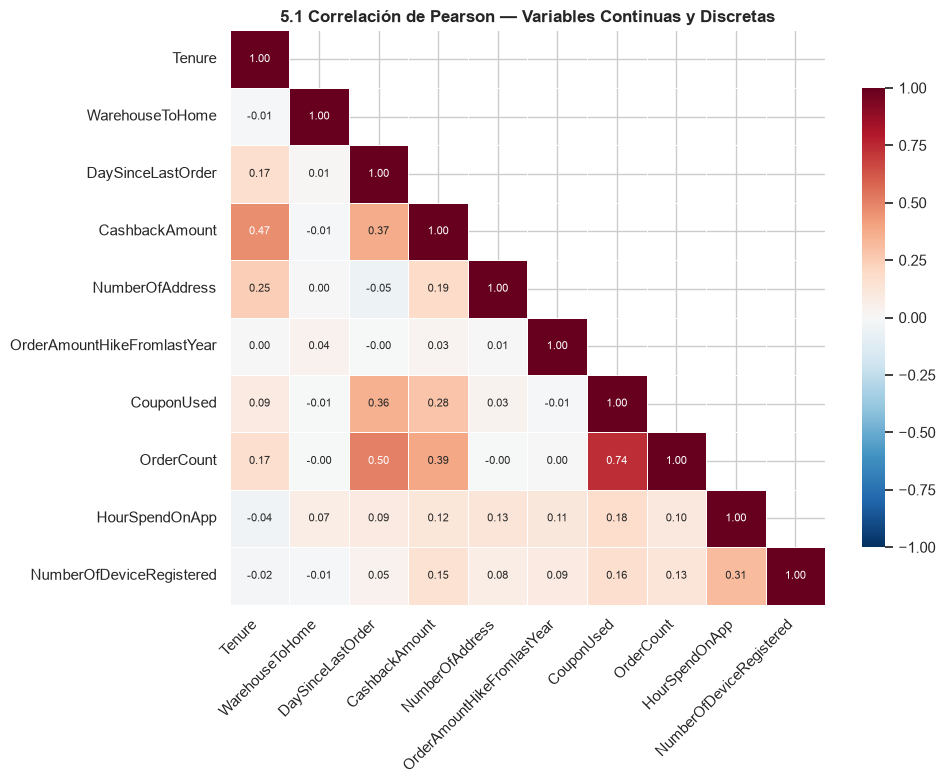

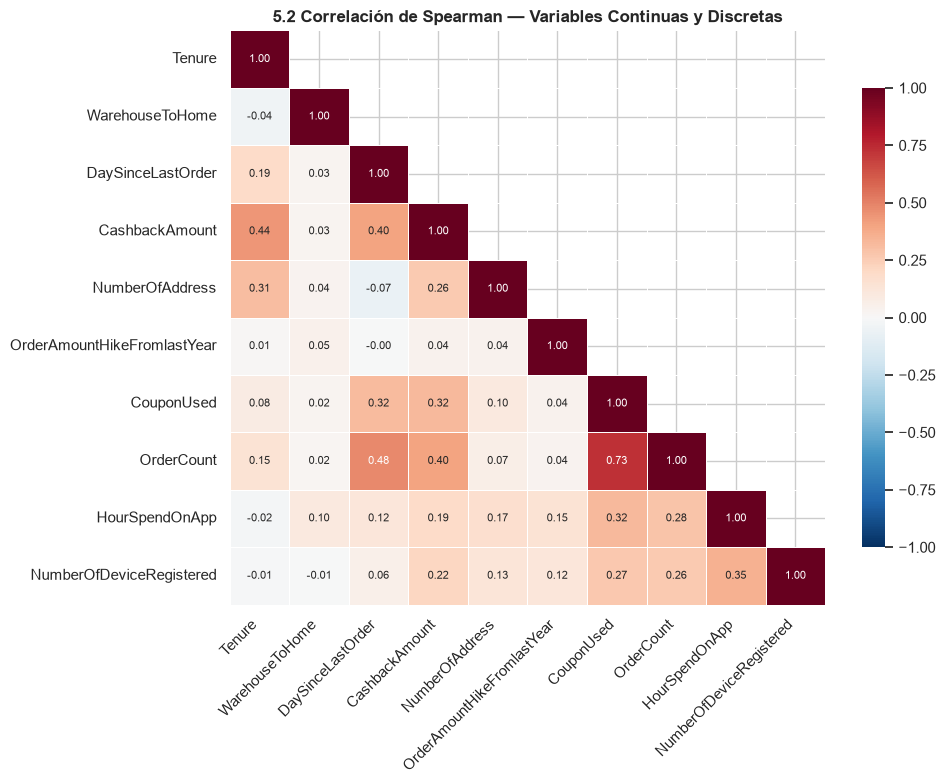

Pares con mayor discrepancia |Pearson - Spearman| (no linealidad o sensibilidad a valores extremos):


|Pearson - Spearman|
OrderCount      HourSpendOnApp                           0.181
                NumberOfDeviceRegistered                 0.139
CouponUsed      HourSpendOnApp                           0.137
                NumberOfDeviceRegistered                 0.102
CashbackAmount  NumberOfAddress                          0.074
NumberOfAddress OrderCount                               0.071

Pares numéricos con |rho de Spearman| >= 0.40:


,,rho_Spearman
CouponUsed,OrderCount,0.728
DaySinceLastOrder,OrderCount,0.478
Tenure,CashbackAmount,0.440
CashbackAmount,OrderCount,0.404
DaySinceLastOrder,CashbackAmount,0.401


,VIF
OrderCount,1.94
CouponUsed,1.72
CashbackAmount,1.53
Tenure,1.34
DaySinceLastOrder,1.31
HourSpendOnApp,1.17
NumberOfDeviceRegistered,1.14
NumberOfAddress,1.12
OrderAmountHikeFromlastYear,1.02
WarehouseToHome,1.01


Nota: Todos los VIF < 5 confirman ausencia de multicolinealidad lineal severa entre las variables numéricas (máximo en OrderCount y CouponUsed por su relación natural de uso de cupones por pedido).


In [17]:
pear = df[num_cols].corr(method="pearson")
spear = df[num_cols].corr(method="spearman")

heatmap(pear, "5.1 Correlación de Pearson — Variables Continuas y Discretas", "05_1_pearson")
heatmap(spear, "5.2 Correlación de Spearman — Variables Continuas y Discretas", "05_2_spearman")
exportar(pear.round(3), "05_corr_pearson")
exportar(spear.round(3), "05_corr_spearman")

dif = (pear - spear).abs().where(np.triu(np.ones(pear.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("Pares con mayor discrepancia |Pearson - Spearman| (no linealidad o sensibilidad a valores extremos):")
display(dif.head(6).round(3).to_frame("|Pearson - Spearman|"))

pares_fuertes = spear.where(np.triu(np.ones(spear.shape), k=1).astype(bool)).stack()
pares_fuertes = pares_fuertes[pares_fuertes.abs() >= 0.40].sort_values(key=abs, ascending=False)
print("Pares numéricos con |rho de Spearman| >= 0.40:")
display(pares_fuertes.round(3).to_frame("rho_Spearman") if len(pares_fuertes) else "ninguno")

Z = df[num_cols].fillna(df[num_cols].median())
vif = pd.Series(np.diag(np.linalg.inv(Z.corr().values)), index=num_cols, name="VIF").sort_values(ascending=False)
display(vif.round(2).to_frame())

print("Nota: Todos los VIF < 5 confirman ausencia de multicolinealidad lineal severa entre las variables numéricas (máximo en OrderCount y CouponUsed por su relación natural de uso de cupones por pedido).")

En esta parte analizamos cómo se relacionan las variables numéricas entre sí. Las correlaciones (Pearson y Spearman) nos dicen si dos variables se mueven juntas; por ejemplo, si aumenta la cantidad de pedidos (OrderCount), también tiende a aumentar el uso de cupones (CouponUsed). Spearman suele ser más confiable aquí porque no se deja engañar tan fácil por valores extremos. Además, calculamos el VIF, que es una métrica para detectar "redundancia" (multicolinealidad). Si tuviéramos un VIF muy alto (mayor a 5 o 10), significaría que dos variables nos están dando exactamente la misma información y deberíamos eliminar una para no confundir a nuestros modelos. Como todos nuestros VIF son bajos, comprobamos que cada variable numérica aporta información única y útil, cumpliendo con el requisito de análisis de características para la fase de modelado.


In [18]:
rho_churn = assoc["tamaño_efecto"].sort_values(key=abs, ascending=False)

print("Fuerza de asociación con Churn (tamaño de efecto extraído de la sección 4):")

display(rho_churn.round(3).to_frame("efecto_con_Churn"))

Fuerza de asociación con Churn (tamaño de efecto extraído de la sección 4):


,efecto_con_Churn
variable,
Tenure,-0.611
DaySinceLastOrder,-0.261
CashbackAmount,-0.254
Complain,0.249
PreferedOrderCat,0.196
MaritalStatus,0.147
NumberOfDeviceRegistered,0.133
WarehouseToHome,0.124
SatisfactionScore,0.104


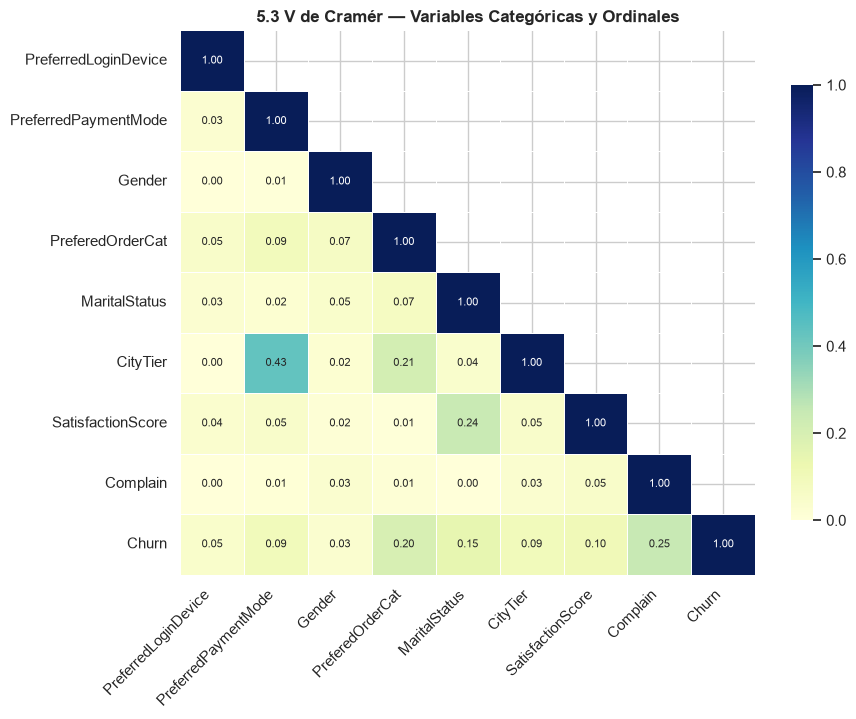

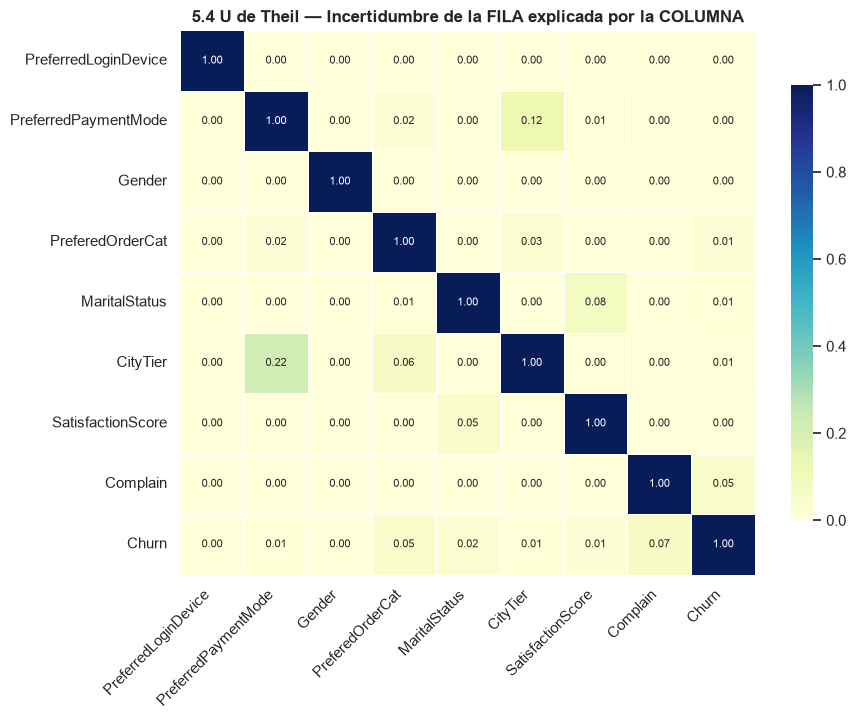

Asociación de cada variable categórica con Churn (V de Cramér):


,V_Cramer
Complain,0.249
PreferedOrderCat,0.196
MaritalStatus,0.147
SatisfactionScore,0.104
PreferredPaymentMode,0.094
CityTier,0.094
PreferredLoginDevice,0.046
Gender,0.032


Proporción de incertidumbre de Churn explicada por cada variable U(Churn | Variable):


,U_Theil
Complain,0.0655
PreferedOrderCat,0.0466
MaritalStatus,0.0245
SatisfactionScore,0.0138
PreferredPaymentMode,0.0109
CityTier,0.0105
PreferredLoginDevice,0.0028
Gender,0.0015


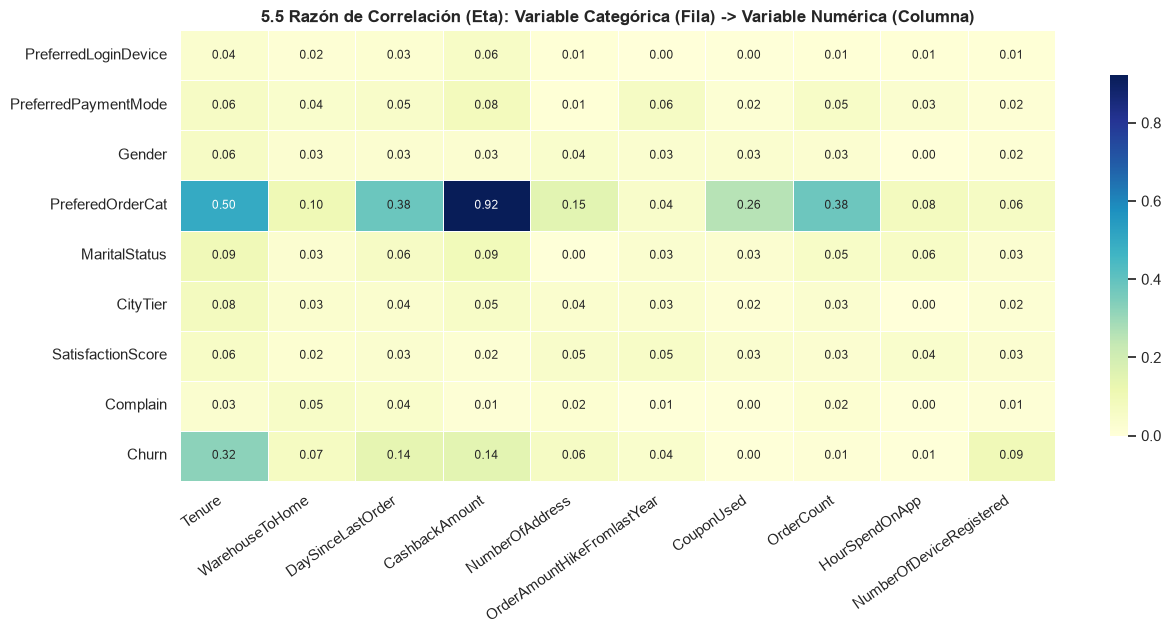

=== ANÁLISIS DEL HALLAZGO ESTRUCTURAL: PreferedOrderCat -> CashbackAmount ===


,count,mean,std,min,median,max
PreferedOrderCat,,,,,,
Mobile Phone,1131,140.17,15.56,0.00,142.00,174.68
Laptop & Accessory,1123,167.67,20.96,0.00,167.81,224.98
Fashion,486,210.84,22.03,145.00,208.82,262.57
Grocery,223,267.10,23.23,211.03,267.04,304.24
Others,150,304.10,13.40,280.41,299.99,324.99


Varianza de CashbackAmount explicada por PreferedOrderCat (eta^2): 84.8%
Interpretación: PreferedOrderCat y CashbackAmount presentan una asociación fuerte (eta² = 84.8%). Las medianas observadas muestran diferencias entre categorías, por ejemplo, Mobile Phone y Grocery. Este patrón ayuda a comprender la estructura de los datos y la distribución de algunos valores faltantes.


In [19]:
cat_todo = nom_cols + ord_cols + bin_cols + [TARGET]

dfc = df[cat_todo].copy()

V = matriz(dfc, cat_todo, cramers_v, simetrica=True)
U = matriz(dfc, cat_todo, theil_u, simetrica=False)

heatmap(V, "5.3 V de Cramér — Variables Categóricas y Ordinales", "05_3_cramer", cmap="YlGnBu", vmin=0, vmax=1)
heatmap(U, "5.4 U de Theil — Incertidumbre de la FILA explicada por la COLUMNA", "05_4_theil", cmap="YlGnBu", vmin=0, vmax=1, triangulo=False)
exportar(V.round(3), "05_assoc_cramer")
exportar(U.round(3), "05_assoc_theil")

print("Asociación de cada variable categórica con Churn (V de Cramér):")
display(V[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("V_Cramer"))
print("Proporción de incertidumbre de Churn explicada por cada variable U(Churn | Variable):")
display(U.loc[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_frame("U_Theil"))

E = pd.DataFrame({c: [eta(df[g], df[c]) for g in cat_todo] for c in num_cols}, index=cat_todo)
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(
    E.astype(float), cmap="YlGnBu", vmin=0, vmax=max(0.3, float(np.nanmax(E.values))),
    annot=True, fmt=".2f", annot_kws={"size": 8.5}, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("5.5 Razón de Correlación (Eta): Variable Categórica (Fila) -> Variable Numérica (Columna)", fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
guardar(fig, "05_5_eta")
plt.show()
exportar(E.round(3), "05_assoc_eta")

print("=== ANÁLISIS DEL HALLAZGO ESTRUCTURAL: PreferedOrderCat -> CashbackAmount ===")
resumen_cb = df.groupby("PreferedOrderCat")["CashbackAmount"].agg(["count", "mean", "std", "min", "median", "max"]).sort_values("median")
display(resumen_cb.round(2))
print(f"Varianza de CashbackAmount explicada por PreferedOrderCat (eta^2): {E.loc['PreferedOrderCat', 'CashbackAmount']**2:.1%}")

print(
    "Interpretación: PreferedOrderCat y CashbackAmount presentan "
    f"una asociación fuerte (eta² = {E.loc['PreferedOrderCat', 'CashbackAmount']**2:.1%}). "
    "Las medianas observadas muestran diferencias entre categorías, "
    "por ejemplo, Mobile Phone y Grocery. Este patrón ayuda a "
    "comprender la estructura de los datos y la distribución de "
    "algunos valores faltantes."
)

En esta etapa cruzamos las variables cualitativas (texto o categorías) contra las demás para ver qué tanta información comparten. La V de Cramér nos muestra asociaciones directas, mientras que la U de Theil nos revela si saber un dato (como el género) nos permite predecir otro. El descubrimiento verdaderamente importante aquí lo arroja el estadístico Eta ($\eta$): existe una relación colosal (Eta = 0.92) entre la categoría de compra (PreferedOrderCat) y el dinero devuelto (CashbackAmount). Esto revela una regla de negocio oculta en los datos: el reembolso que recibe un cliente está prácticamente predeterminado por el tipo de producto que compra. Este hallazgo nos ayudará a limpiar variables redundantes más adelante, simplificando el trabajo para nuestros modelos de Machine Learning.


## 6. Visualización multivariada y perfilamiento con datos faltantes

1. **Matriz de Dispersión (`pairplot`) de Variables Continuas por `Churn`**
2. **Matriz de Dispersión coloreada por Presencia de Datos Faltantes**, evidenciando visualmente cómo los registros con datos faltantes se agrupan en bandas específicas de `CashbackAmount` (reflejo directo de su concentración en categorías de `PreferedOrderCat`).
3. **Comparativa de Perfiles Categóricos según Presencia de Datos Faltantes**

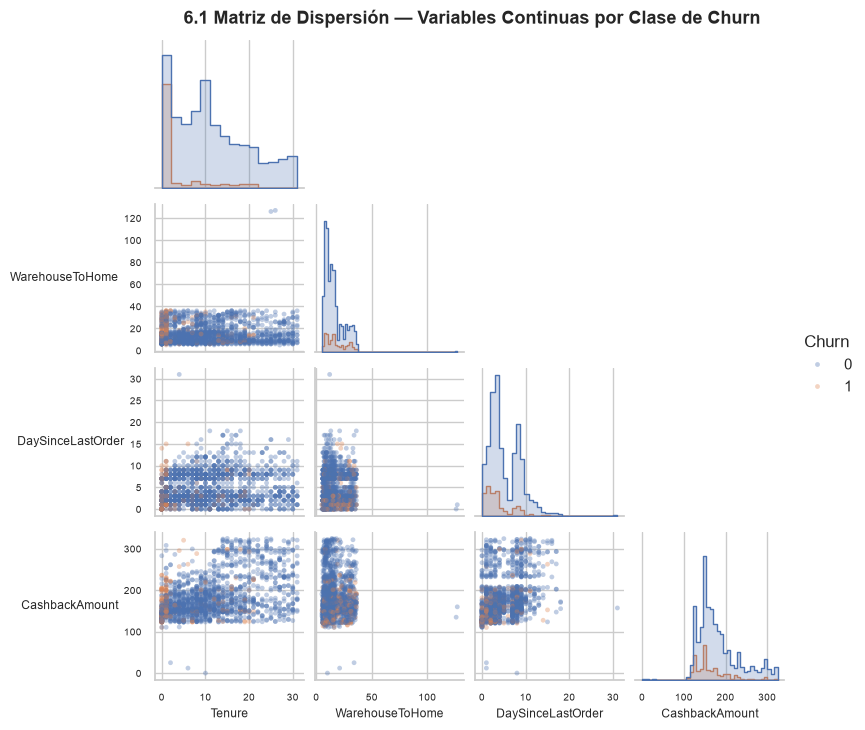

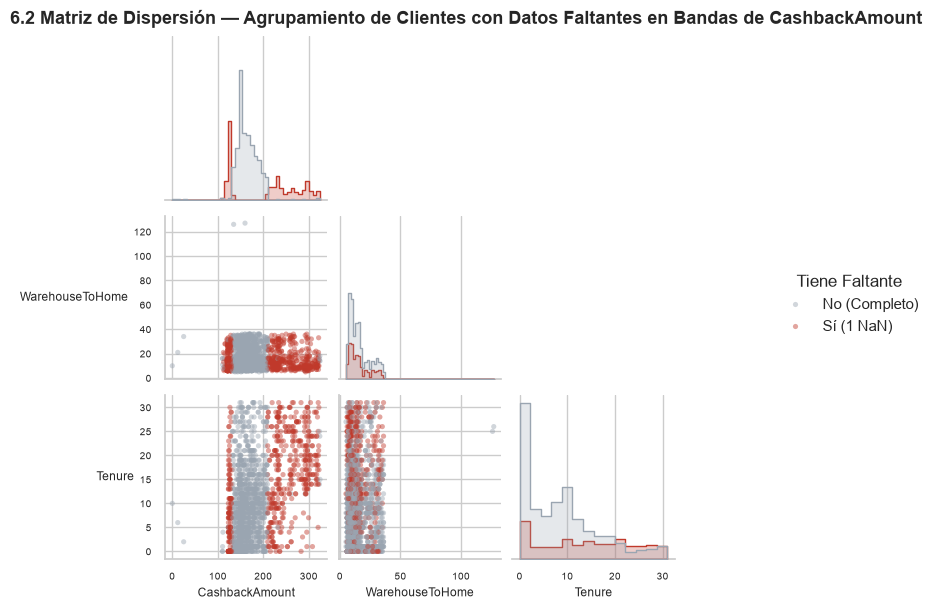

In [20]:
muestra = df.sample(min(len(df), 2000), random_state=SEED)

def ajustar_etiquetas(g, tam=8.5):
    for ax in g.axes.flatten():
        if ax is None:
            continue
        ax.set_xlabel(ax.get_xlabel(), fontsize=tam)
        ax.set_ylabel(ax.get_ylabel(), fontsize=tam, rotation=0, ha="right", va="center")
        ax.tick_params(labelsize=7.5)

g1 = sns.pairplot(
    muestra, vars=cont_cols, hue=TARGET, palette=COLORES, corner=True, diag_kind="hist",
    plot_kws=dict(alpha=0.35, s=12, linewidth=0),
    diag_kws=dict(common_norm=False, element="step"), height=1.8
)
ajustar_etiquetas(g1)
g1.figure.suptitle("6.1 Matriz de Dispersión — Variables Continuas por Clase de Churn", y=1.02, fontsize=13, fontweight="bold")
guardar(g1.figure, "06_1_scatter_matrix_continuas_churn")
plt.show()

m2 = muestra.assign(**{"Tiene Faltante": muestra[cols_na].isna().any(axis=1).map({True: "Sí (1 NaN)", False: "No (Completo)"})})
g2 = sns.pairplot(
    m2, vars=["CashbackAmount", "WarehouseToHome", "Tenure"], hue="Tiene Faltante",
    palette={"No (Completo)": "#9aa5b1", "Sí (1 NaN)": "#c0392b"}, corner=True, diag_kind="hist",
    plot_kws=dict(alpha=0.45, s=14, linewidth=0),
    diag_kws=dict(common_norm=False, element="step"), height=2.0
)
ajustar_etiquetas(g2)
g2.figure.suptitle("6.2 Matriz de Dispersión — Agrupamiento de Clientes con Datos Faltantes en Bandas de CashbackAmount", y=1.02, fontsize=13, fontweight="bold")
guardar(g2.figure, "06_2_scatter_matrix_faltantes")

plt.show()

En esta sección cruzamos las variables continuas de dos en dos para ver cómo interactúan simultáneamente (análisis multivariado). La primera matriz (6.1) nos ayuda a buscar si existe alguna combinación de dos variables que separe claramente a los clientes que abandonan de los que se quedan, aunque en la práctica los datos suelen estar bastante mezclados y por eso requerimos modelos complejos. La segunda gráfica (6.2) es evidencia visual consistente con el hallazgo de la sección 2.4: al colorear de rojo a los clientes con datos faltantes, podemos ver perfectamente que no están dispersos al azar por todo el gráfico, sino que forman "líneas" o bandas estrictas que dependen de cuánto dinero se les devolvió (CashbackAmount). Esto refuerza un patrón compatible con MAR, aunque no confirma el mecanismo, y justifica nuestro enfoque de tratamiento de datos nulos.

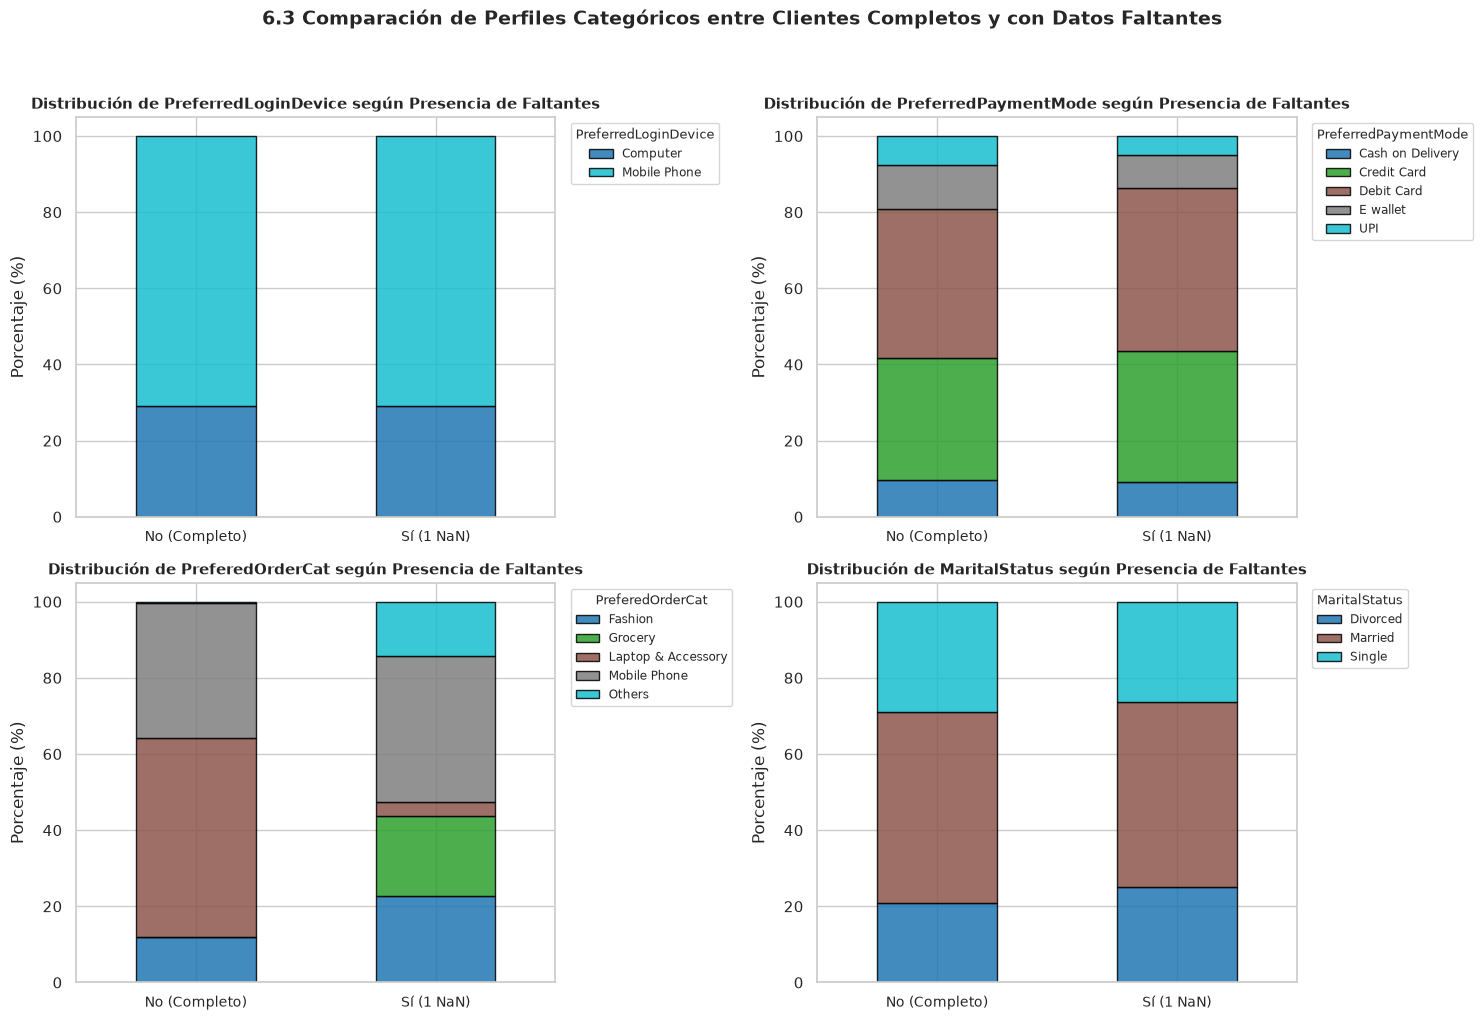

In [20]:
cats_a_analizar = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat", "MaritalStatus"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
axes = axes.flatten()

for i, col in enumerate(cats_a_analizar):
    ct = pd.crosstab(m2["Tiene Faltante"], m2[col], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=axes[i], colormap="tab10", edgecolor="black", alpha=0.85)
    axes[i].set_ylabel("Porcentaje (%)")
    axes[i].set_xlabel("")
    axes[i].set_xticklabels(ct.index, rotation=0, fontsize=10)
    axes[i].legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5, title_fontsize=9)
    axes[i].set_ylim(0, 105)
    axes[i].set_title(f"Distribución de {col} según Presencia de Faltantes", fontsize=11, fontweight="bold")

fig.suptitle("6.3 Comparación de Perfiles Categóricos entre Clientes Completos y con Datos Faltantes", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
guardar(fig, "06_3_comparativa_categoricas_faltantes")

plt.show()

Con estas gráficas armamos el "perfil" del cliente que tiene datos faltantes y lo comparamos cara a cara con el cliente que tiene su información completa. Lo que observamos aquí es una confirmación descriptiva de lo que descubrimos con los números: los clientes con datos faltantes no son una muestra representativa de toda la base, sino que están altamente sesgados hacia ciertas preferencias. Especialmente en la gráfica de la categoría de orden preferida (PreferedOrderCat), notaremos que la composición de los colores cambia drásticamente entre un grupo y otro. Esto refuerza un patrón compatible con MAR, sin demostrar el mecanismo: el perfil de compra del cliente define en qué rango de reembolso cae y, por consiguiente, si su registro sufrirá un borrado de información en este sistema.

## 7. Evaluación experimental de pipelines de imputación

Para decidir con base qué método de imputación vamos a usar en el pipeline y no irnos a ciegas, corrimos una prueba controlada usando **validación cruzada agrupada y estratificada de 5 pliegues (`StratifiedGroupKFold`) solo sobre `train`**, así mantenemos los grupos separados y evitamos fuga de información entre pliegues.

### Estrategias de imputación evaluadas
1. **`SimpleImputer (Mediana) - Sin Indicadores`:** Rellena con la mediana general de cada columna sin dejar marcas de dónde había faltantes; es lo más básico, pero ignora patrones tipo MAR y borra qué dato faltaba.
2. **`SimpleImputer (Mediana) + MissingIndicators`:** Imputa con la mediana y además agrega indicadores booleanos de ausencia (`isna`) para las 7 variables con nulos, para que el modelo sepa cuándo faltó un dato.
3. **`GroupMedianImputer (por PreferedOrderCat) + MissingIndicators`:** Un transformador que hicimos para imputar la mediana según la categoría de `PreferedOrderCat` del cliente (aprovechando la relación fuerte con $\eta = 0.92$ y $V = 0.74$), sumando también los indicadores de ausencia.
4. **`KNNImputer (k=15) + MissingIndicators`:** Estima los faltantes mirando los 15 vecinos más cercanos en el espacio escalado, junto con los indicadores de ausencia.
5. **`IterativeImputer (MICE) + MissingIndicators`:** Hace imputación multivariada de forma iterativa (usando regresión bayesiana encadenada) más los indicadores de ausencia.
6. **`Soporte Nativo de Nulos (Sin Imputar, con y sin indicadores)`:** Se prueba en `HistGradientBoostingClassifier` en dos versiones: dejando que el modelo maneje los nulos directamente sin imputar, tanto sin indicadores explícitos como agregándolos.

### Modelos y métricas de evaluación
Como la clase positiva (`Churn`) está desbalanceada (alrededor del 16.58 %), probamos tres tipos de modelos distintos (`LogisticRegression`, `RandomForestClassifier` y `HistGradientBoostingClassifier`) y miramos **ROC-AUC**, **PR-AUC (Average Precision)** y **F1-Score** para comparar bien cómo rinden.

In [21]:
X_train = train.drop(columns=[TARGET]).copy()
y_train = train[TARGET].copy()

def cv_group_splits(groups, n_splits=5, n_repeats=1, seed=SEED):
    splits = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed + r,
        )
        splits.extend(list(sgkf.split(X_train, y_train, groups=groups)))
    return splits

CV_TUNING = cv_group_splits(grupos_train, n_splits=5, n_repeats=1, seed=SEED)
CV_REP = cv_group_splits(grupos_train, n_splits=5, n_repeats=5, seed=SEED + 1)
cv_tuning = CV_TUNING

all_num_features = cont_cols + disc_cols + ord_cols + bin_cols
all_cat_features = nom_cols

configurar_columnas(all_num_features, all_cat_features, cols_na)


En esta sección hemos diseñado y configurado diferentes "tuberías" o pipelines de procesamiento que prueban distintas formas de lidiar con los datos nulos de nuestros clientes. En lugar de escoger un método al azar, creamos desde el más básico (poner la mediana de todos) hasta métodos matemáticos complejos (KNN o MICE). También incluimos nuestra propia lógica de negocio calculando medianas agrupadas por la categoría de producto, e incluso permitimos que el modelo decida por sí solo qué hacer con los nulos ("Soporte Nativo"). La incorporación de MissingIndicators es vital porque, como vimos en secciones anteriores, el simple hecho de que falte un dato ya es un indicador de que el cliente pertenece a una banda específica de reembolsos. Esto asegura que nuestros modelos no solo adivinen qué valor faltaba, sino que también aprendan de la ausencia del mismo.

,Modelo,Estrategia de Imputación,ROC-AUC (Media),ROC-AUC (Std),PR-AUC (Media),PR-AUC (Std),F1-Score (Media)
0,HistGradientBoosting,Mediana por Segmento (PreferedOrderCat) + Miss...,0.9380,0.0088,0.8128,0.0218,0.7084
1,HistGradientBoosting,IterativeImputer (MICE) + MissingIndicators,0.9380,0.0072,0.8117,0.0218,0.7021
2,HistGradientBoosting,KNNImputer (k=15) + MissingIndicators,0.9379,0.0077,0.8079,0.0265,0.6885
3,HistGradientBoosting,Mediana Simple (Sin Indicadores),0.9362,0.0099,0.8023,0.0319,0.6959
4,HistGradientBoosting,Mediana Simple + MissingIndicators,0.9376,0.0065,0.8015,0.0260,0.7004
5,HistGradientBoosting,Nativo con Nulos (Sin Imputar) - Sin Indicadores,0.9365,0.0093,0.8011,0.0193,0.6920
6,HistGradientBoosting,Nativo con Nulos (Sin Imputar) + MissingIndica...,0.9365,0.0093,0.8011,0.0193,0.6920
7,LogisticRegression,IterativeImputer (MICE) + MissingIndicators,0.8927,0.0073,0.6878,0.0270,0.6034
8,LogisticRegression,KNNImputer (k=15) + MissingIndicators,0.8909,0.0084,0.6870,0.0373,0.6018
9,LogisticRegression,Mediana por Segmento (PreferedOrderCat) + Miss...,0.8911,0.0083,0.6852,0.0324,0.5937


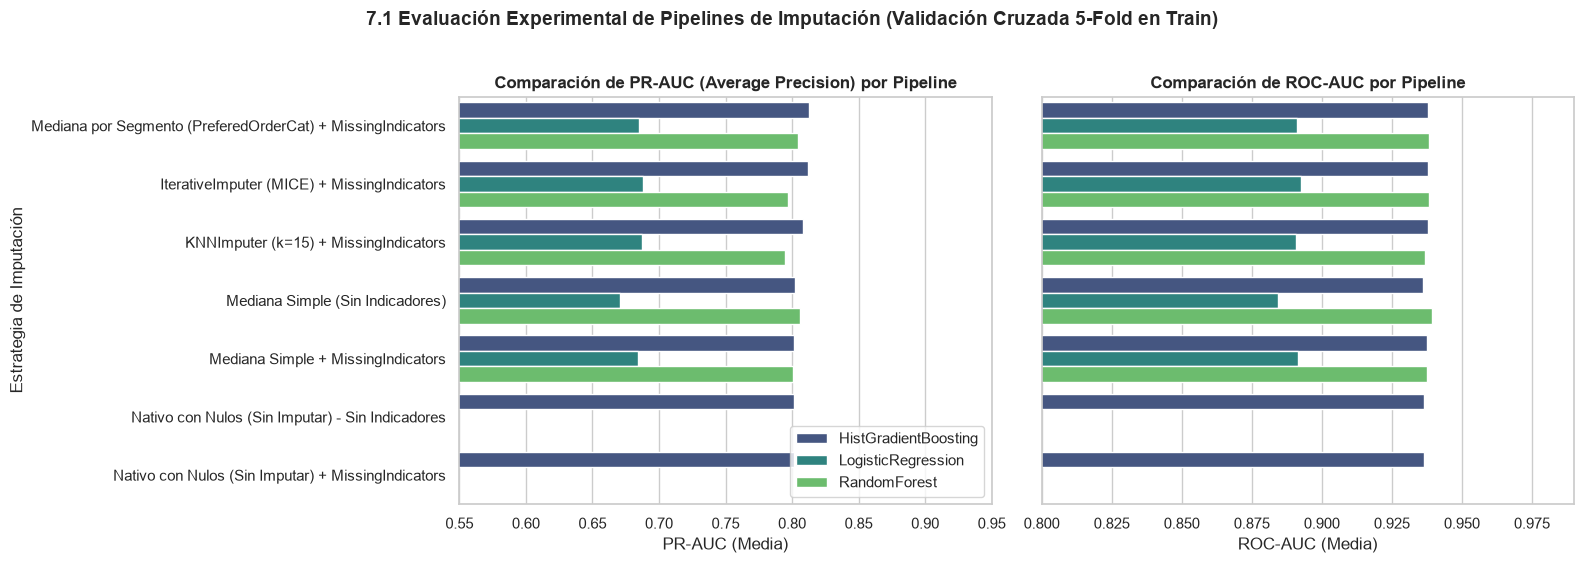

In [22]:
estrategias = [
    "Mediana Simple (Sin Indicadores)",
    "Mediana Simple + MissingIndicators",
    "Mediana por Segmento (PreferedOrderCat) + MissingIndicators",
    "KNNImputer (k=15) + MissingIndicators",
    "IterativeImputer (MICE) + MissingIndicators"
]

modelos = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=6, learning_rate=0.06, random_state=SEED)
}

cv_exp = CV_TUNING
resultados_exp = []

for nombre_est in estrategias:
    for nombre_mdl, clf in modelos.items():
        pipe = Pipeline([
            ("prep", construir_preprocesador(nombre_est)),
            ("clf", clf)
        ])
        scores = cross_validate(
            pipe, X_train, y_train, cv=cv_exp,
            scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
            n_jobs=-1
        )
        resultados_exp.append({
            "Modelo": nombre_mdl,
            "Estrategia de Imputación": nombre_est,
            "ROC-AUC (Media)": round(scores["test_roc_auc"].mean(), 4),
            "ROC-AUC (Std)": round(scores["test_roc_auc"].std(), 4),
            "PR-AUC (Media)": round(scores["test_pr_auc"].mean(), 4),
            "PR-AUC (Std)": round(scores["test_pr_auc"].std(), 4),
            "F1-Score (Media)": round(scores["test_f1"].mean(), 4)
        })

pipe_nativo_sin = Pipeline([
    ("prep", construir_preprocesador("Nativo con Nulos (Sin Imputar) - Sin Indicadores")),
    ("clf", modelos["HistGradientBoosting"])
])
scores_nat_sin = cross_validate(
    pipe_nativo_sin, X_train, y_train, cv=cv_exp,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
    n_jobs=-1
)
resultados_exp.append({
    "Modelo": "HistGradientBoosting",
    "Estrategia de Imputación": "Nativo con Nulos (Sin Imputar) - Sin Indicadores",
    "ROC-AUC (Media)": round(scores_nat_sin["test_roc_auc"].mean(), 4),
    "ROC-AUC (Std)": round(scores_nat_sin["test_roc_auc"].std(), 4),
    "PR-AUC (Media)": round(scores_nat_sin["test_pr_auc"].mean(), 4),
    "PR-AUC (Std)": round(scores_nat_sin["test_pr_auc"].std(), 4),
    "F1-Score (Media)": round(scores_nat_sin["test_f1"].mean(), 4)
})

pipe_nativo = Pipeline([
    ("prep", construir_preprocesador("Nativo con Nulos (Sin Imputar) + MissingIndicators")),
    ("clf", modelos["HistGradientBoosting"])
])
scores_nat = cross_validate(
    pipe_nativo, X_train, y_train, cv=cv_exp,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
    n_jobs=-1
)
resultados_exp.append({
    "Modelo": "HistGradientBoosting",
    "Estrategia de Imputación": "Nativo con Nulos (Sin Imputar) + MissingIndicators",
    "ROC-AUC (Media)": round(scores_nat["test_roc_auc"].mean(), 4),
    "ROC-AUC (Std)": round(scores_nat["test_roc_auc"].std(), 4),
    "PR-AUC (Media)": round(scores_nat["test_pr_auc"].mean(), 4),
    "PR-AUC (Std)": round(scores_nat["test_pr_auc"].std(), 4),
    "F1-Score (Media)": round(scores_nat["test_f1"].mean(), 4)
})

df_resultados_imp = pd.DataFrame(resultados_exp).sort_values(["Modelo", "PR-AUC (Media)"], ascending=[True, False])
display(df_resultados_imp.reset_index(drop=True))
exportar(df_resultados_imp, "07_benchmark_pipelines_imputacion")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)

sns.barplot(
    data=df_resultados_imp, y="Estrategia de Imputación", x="PR-AUC (Media)",
    hue="Modelo", palette="viridis", ax=axes[0]
)
axes[0].set_title("Comparación de PR-AUC (Average Precision) por Pipeline", fontweight="bold")
axes[0].set_xlim(0.55, 0.95)
axes[0].legend(loc="lower right")

sns.barplot(
    data=df_resultados_imp, y="Estrategia de Imputación", x="ROC-AUC (Media)",
    hue="Modelo", palette="viridis", ax=axes[1], legend=False
)
axes[1].set_title("Comparación de ROC-AUC por Pipeline", fontweight="bold")
axes[1].set_xlim(0.80, 0.99)
axes[1].set_ylabel("")

plt.suptitle("7.1 Evaluación Experimental de Pipelines de Imputación (Validación Cruzada 5-Fold en Train)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
guardar(fig, "07_comparativa_pipelines_imputacion")

plt.show()

Al observar los resultados de esta validación cruzada, notamos que las diferencias de rendimiento entre usar una imputación básica o una muy avanzada son pequeñas pero no despreciables: en HGB, la diferencia frente a las variantes de mediana es de 1,05 a 1,13 pp y frente al soporte nativo llega a 1,17 pp; en Regresión Logística llega a 1,69 pp. El modelo paramétrico de Regresión Logística sí evidencia una ganancia al aprovechar los indicadores booleanos de ausencia. Por lo tanto, dado que métodos costosos computacionalmente como KNN o la regresión iterativa (MICE) no logran una ventaja real que justifique su tiempo de cómputo, la decisión más sólida y eficiente para nuestra arquitectura final es emplear la **mediana por segmento (`PreferedOrderCat`) + indicadores de ausencia**, que es la estrategia seleccionada por el benchmark de HGB (0,8128). Esta estrategia garantiza que preservemos la valiosa señal predictiva de los valores nulos mediante un enfoque directo y ligero.


## 8. Resumen ejecutivo y decisiones de arquitectura

In [23]:
sig = tabla_na_churn[tabla_na_churn["asociada_a_churn"] == "SÍ"].index.tolist()
asociadas = tabla_na_churn[tabla_na_churn["q_BH"] < ALPHA]

mayor_or = asociadas[asociadas["OR"] > 1].index.tolist()
menor_or = asociadas[asociadas["OR"] < 1].index.tolist()

estrategia_recomendada = (
    df_resultados_imp[df_resultados_imp["Modelo"] == "HistGradientBoosting"]
    .sort_values("PR-AUC (Media)", ascending=False)
    .iloc[0]["Estrategia de Imputación"]
)
mejor_fila = df_resultados_imp[
    df_resultados_imp["Estrategia de Imputación"] == estrategia_recomendada
].sort_values("PR-AUC (Media)", ascending=False).iloc[0]
mejor_global_imp = df_resultados_imp.sort_values("PR-AUC (Media)", ascending=False).iloc[0]

riesgo_txt = ", ".join(f"{v} (OR={tabla_na_churn.loc[v, 'OR']})" for v in mayor_or) or "ninguno"
protector_txt = ", ".join(f"{v} (OR={tabla_na_churn.loc[v, 'OR']})" for v in menor_or) or "ninguno"

print("==========================================================================")
print("           RESUMEN EJECUTIVO DE HALLAZGOS (PARTICIÓN: TRAIN)              ")
print("==========================================================================")
print("\n1. DIAGNÓSTICO DE DATOS FALTANTES Y MECANISMO DE AUSENCIA:")
print(f"   • Variables con OR > 1: {mayor_or}.")
print(f"   • Variables con OR < 1: {menor_or}.")
print(f"   • Variables con faltantes ({len(cols_na)}): Rango entre {resumen_na['% faltante'].min():.2f}% y {resumen_na['% faltante'].max():.2f}%.")
print(f"   • Exclusión mutua: {tiene_na.mean():.1%} de los representantes ({int(tiene_na.sum())} filas) tienen exactamente 1 valor faltante (máximo 1 NaN por fila).")
print(f"   • Compensación de efectos en agregación: Tasa de Churn con 1 faltante = {100 * y[tiene_na].mean():.1f}% vs. sin faltantes = {100 * y[~tiene_na].mean():.1f}% (p = {p_f:.3f}).")
print(f"   • Ausencia asociada individualmente a Churn (q_BH < 0.05): {len(sig)} de {len(cols_na)} variables -> {sig}.")
print(f"     - Factores de riesgo aparentes (OR > 1): {riesgo_txt}.")
print(f"     - Factores protectores aparentes (OR < 1): {protector_txt}.")
print("   • Patrón de ausencia compatible con MAR: los valores faltantes se concentran en rangos específicos de CashbackAmount.")
print("\n2. ASOCIACIONES Y ESTRUCTURA MULTIVARIADA:")
print(f"   • VIF máximo entre las {len(num_cols)} variables numéricas: {vif.index[0]} (VIF = {vif.iloc[0]:.2f} < 5.0 -> sin multicolinealidad severa).")
print(f"   • Asociación entre PreferedOrderCat y CashbackAmount: eta² = {E.loc['PreferedOrderCat', 'CashbackAmount']**2:.1%}.")
print(f"   • Top 4 predictores globales de Churn (Tamaño de efecto absoluto): {[(k, round(float(v), 3)) for k, v in rho_churn.head(4).items()]}.")
vch = V[TARGET].drop(TARGET).sort_values(ascending=False)
print(f"   • Top 4 predictores categóricos de Churn (V de Cramér): {[(k, round(float(v), 3)) for k, v in vch.head(4).items()]}.")
print("\n3. DECISIÓN EXPERIMENTAL DE IMPUTACIÓN Y ARQUITECTURA:")
print(f"   • Estrategia seleccionada: {mejor_fila['Estrategia de Imputación']}.")
print(f"   • Mejor modelo con la estrategia seleccionada: {mejor_fila['Modelo']} | PR-AUC = {mejor_fila['PR-AUC (Media)']:.4f} (±{mejor_fila['PR-AUC (Std)']:.4f})")
print(f"   • Mejor resultado global del benchmark de imputación: {mejor_global_imp['Modelo']} + {mejor_global_imp['Estrategia de Imputación']} | PR-AUC = {mejor_global_imp['PR-AUC (Media)']:.4f}")
print("==========================================================================")


           RESUMEN EJECUTIVO DE HALLAZGOS (PARTICIÓN: TRAIN)              

1. DIAGNÓSTICO DE DATOS FALTANTES Y MECANISMO DE AUSENCIA:
   • Variables con OR > 1: ['Tenure', 'WarehouseToHome'].
   • Variables con OR < 1: ['OrderCount', 'OrderAmountHikeFromlastYear', 'CouponUsed'].
   • Variables con faltantes (7): Rango entre 4.11% y 5.78%.
   • Exclusión mutua: 33.2% de los representantes (1032 filas) tienen exactamente 1 valor faltante (máximo 1 NaN por fila).
   • Compensación de efectos en agregación: Tasa de Churn con 1 faltante = 15.6% vs. sin faltantes = 15.7% (p = 1.000).
   • Ausencia asociada individualmente a Churn (q_BH < 0.05): 5 de 7 variables -> ['Tenure', 'WarehouseToHome', 'OrderCount', 'OrderAmountHikeFromlastYear', 'CouponUsed'].
     - Factores de riesgo aparentes (OR > 1): Tenure (OR=2.66), WarehouseToHome (OR=2.4).
     - Factores protectores aparentes (OR < 1): OrderCount (OR=0.37), OrderAmountHikeFromlastYear (OR=0.3), CouponUsed (OR=0.18).
   • Patrón de ausenci

In [24]:
guardar_estado("1_eda",
    SEED=SEED,
    TARGET=TARGET,
    train=train,
    test=test,
    X_train=X_train,
    y_train=y_train,
    w_train=w_train,
    grupos_train=grupos_train,
    w_test=w_test,
    grupos_test=grupos_test,
    CV_TUNING=CV_TUNING,
    CV_REP=CV_REP,
    estrategia_recomendada=estrategia_recomendada,
    nom_cols=nom_cols,
    bin_cols=bin_cols,
    ord_cols=ord_cols,
    disc_cols=disc_cols,
    cont_cols=cont_cols,
    num_cols=num_cols,
    cat_vars=cat_vars,
    cols_na=cols_na,
    all_num_features=all_num_features,
    all_cat_features=all_cat_features,
    assoc=assoc,
    rho_churn=rho_churn,
    vif=vif,
    resumen_na=resumen_na,
    tabla_na_churn=tabla_na_churn,
    df_resultados_imp=df_resultados_imp,
)


WindowsPath('C:/Users/ASUS/Desktop/V8-final/data/processed/estado_1_eda.joblib')

## Cierre del análisis exploratorio

Con este EDA nos quedamos con tres ideas clave para seguir adelante:
1. Los datos faltantes tienen un patrón bien marcado y compatible con MAR, aunque no podemos darlo por confirmado del todo sin conocer el origen exacto de los datos.
2. En la prueba con HGB, imputar por mediana según segmento más indicadores de ausencia fue lo que mejor rindió (0,8128), así que esa es la estrategia que elegimos.
3. Las 10 variables numéricas no muestran problemas graves de multicolinealidad (el VIF más alto es 1,94) y las 6 discretas quedaron bien clasificadas.

Ya con esto claro, pasamos a armar el pipeline de preprocesamiento y a entrenar los modelos en los siguientes notebooks.